# M28 · Matrice de Gram, montée sur l'entrée et lois tronquées — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m28_gram_echantillonnage/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M28.1 à M28.7, M28.11 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M28.13 | Une configuration de points de matrice de Gram donnée, par le théorème spectral · `points_from_gram` | 🔨 | ★★ | 25 |
|  | M28.14 | Tempérer une loi donnée par ses probabilités, et le plus petit ensemble de masse donnée · `temper`, `smallest_mass_set` | 🔨 | ★★ | 30 |
| B | M28.15 | Prédire ce que deviennent un pas η∇f et un pas normalisé quand la fonction est multipliée par 1 000, puis vérifier | 🔮 | ★ | 15 |
|  | M28.16 | Des motifs rayés de fréquence croissante jusqu'au damier : leur variation totale, et ce qu'en laissent un flou 3 × 3 et dix pas de descente sur la variation totale | 🎨 | ★ | 20 |
| C | M28.17 | Chasse à l'erreur : un double centrage fait sur les distances au lieu de leurs carrés, une montée qui coupe le gradient au lieu du point, une prépériode comptée dans la période | 🐛 | ★ | 20 |
|  | M28.18 | Un test de propriété : la configuration rendue redonne la matrice de Gram et les distances, pour des points tirés au hasard | 🛠️ | ★ | 15 |
| D | M28.19 | Défi : redessiner la carte de 30 villes quand un quart des distances manquent, à moins de 1 km en moyenne après alignement | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : une matrice de Gram et une matrice des moments, un double centrage et une carte, une montée projetée, la variation totale d'une barre, des étoffes rayées, une prévision refroidie et tronquée, des suites qui bouclent, et un pont vers la température sur des scores.
- Écrire les trois fonctions de `mymath/sampling.py` (`points_from_gram`, `temper`, `smallest_mass_set`) et les tester.
- Prédire ce qu'un changement d'unité fait à un pas de montée, dessiner des motifs rayés et leur lissage, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** $\mathbf{G} = \mathbf{X}\mathbf{X}^\top$, $\lVert\mathbf{x}_i - \mathbf{x}_j\rVert^2 = G_{ii} + G_{jj} - 2G_{ij}$ ; pour des points centrés, $\mathbf{G} = -\frac12\mathbf{J}\mathbf{D}^{(2)}\mathbf{J}$ (les **carrés** des distances), et les colonnes $\sqrt{\lambda_k}\,\mathbf{q}_k$ donnent une carte à une isométrie près. Montée projetée : $\mathbf{x} \leftarrow \operatorname{clip}(\mathbf{x} + \eta\,\mathbf{s})$, on coupe le **point** ; le pas normalisé ne voit pas l'unité de $f$. $\mathrm{VT}(\mathbf{x}) = \mathbf{x}^\top\mathbf{L}\mathbf{x}$, gradient $2\mathbf{L}\mathbf{x}$ ; un motif de fréquence $f$ : rapport $4\sin^2(\pi f)$, gain $\frac{1 + 2\cos 2\pi f}{3}$. Température : $p_i^{1/T}$ renormalisé ; top-p : le plus petit ensemble de masse $\ge m$ ; $\mathrm{KL}(\mathbf{p}_S \,\|\, \mathbf{p}) = -\ln P(S)$. Période : la longueur du cycle, sans la queue.

## Partie 0 · Vérifier tes exercices papier (✏️ M28.1 à M28.7 ; 🔗 M28.11)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question (« a number » sans décimales : la valeur exacte, ces calculs tombent juste) ;
- une liste `[0.2, -1]`, dans l'ordre que dit la question ; un ensemble d'issues comme la liste de leurs numéros, `[4, 0, 2]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- un intervalle entre guillemets, en notation française, avec des points décimaux, `"]2.5 ; 4]"` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions where the calculation is exact)
import itertools
import math
from fractions import Fraction as F

import numpy as np
from scipy import linalg


def floats(values):
    """A number, a vector or a matrix (fractions, NumPy) as a float or nested lists of floats (-0.0 written 0.0)."""
    return (np.round(np.asarray(values, dtype=float), 12) + 0.0).tolist()


def sq_dists(Z):
    """The matrix of the squared distances between the rows of Z."""
    Z = np.asarray(Z, dtype=float)
    return ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=-1)


def eigen_desc(S):
    """The eigenvalues of a symmetric matrix, in decreasing order (scipy.linalg.eigh), rounded to 1e-9."""
    return floats(np.round(linalg.eigh(np.asarray(S, dtype=float), eigvals_only=True)[::-1], 9))


def nonzero_desc(S):
    """The eigenvalues of a symmetric matrix larger than 1e-9, in decreasing order."""
    return [v for v in eigen_desc(S) if v > 1e-9]


# M28.1: the four beacons, in rows (m)
X_1 = np.array([[3, 1], [1, 3], [-2, 0], [0, -2]], dtype=float)
G_1 = (X_1 @ X_1.T).tolist()


def from_point_0(rule):
    """rule(G_ii, G_jj, G_ij) for i = 1 and j = 2, 3, 4 (the first point against the three others)."""
    return [float(rule(G_1[0][0], G_1[j][j], G_1[0][j])) for j in (1, 2, 3)]


# M28.2: the rhombus A, B, C, D (km): AB = BC = CD = DA = 29, AC = 40, BD = 42; e) AC = 50
D_2 = np.array([[0, 29, 40, 29], [29, 0, 29, 42], [40, 29, 0, 29], [29, 42, 29, 0]], dtype=float)
D2_2 = D_2 ** 2
D2_2E = D2_2.copy()
D2_2E[0, 2] = D2_2E[2, 0] = 50.0 ** 2


def double_centering(M):
    """−½ J M J with the centering matrix J = I − 11ᵀ/n."""
    n = len(M)
    J = np.eye(n) - np.ones((n, n)) / n
    return -0.5 * J @ np.asarray(M, dtype=float) @ J


def spectral_map(G, root=True):
    """The map of the statement: column k = √λ_k q_k (root=False: λ_k q_k), the eigenvalues > 1e-9 by decreasing value
    (scipy.linalg.eigh), and in each column the first coordinate of absolute value > 1e-8 made positive."""
    w, V = linalg.eigh(np.asarray(G, dtype=float))
    w, V = w[::-1], V[:, ::-1]
    keep = w > 1e-9
    X = V[:, keep] * (np.sqrt(w[keep]) if root else w[keep])
    for k in range(X.shape[1]):
        first = np.flatnonzero(np.abs(X[:, k]) > 1e-8)[0]
        if X[first, k] < 0:
            X[:, k] = -X[:, k]
    return np.round(X, 9) + 0.0


# M28.3: four emitters in [0, 1]
W_3 = np.array([2.0, -1.0, 2.0, 4.0])
A_3 = np.array([[5, -1, 0, 0], [-1, 5, 0, 0], [0, 0, 6, -2], [0, 0, -2, 3]], dtype=float)
X0_3 = np.array([0.3, 0.3, 0.6, 0.92])
ETA_3 = 0.2
BEST_3 = (W_3 > 0).astype(float)                       # the vertex of the box that maximizes wᵀx
GAP_3 = np.abs(BEST_3 - X0_3)                          # the distance of each coordinate to its bound
VERTICES_3 = [np.array(v, dtype=float) for v in itertools.product([0, 1], repeat=4)]


def first_step_3(stop):
    """The first t >= 1 such that stop(x_t, x_(t−1)), for the projected ascent clip(x + η w, 0, 1) from x0."""
    previous, x = X0_3, np.clip(X0_3 + ETA_3 * W_3, 0, 1)
    for t in itertools.count(1):
        if stop(x, previous):
            return t
        previous, x = x, np.clip(x + ETA_3 * W_3, 0, 1)


# M28.4: a bar with free ends (°C)
X_4 = np.array([8.0, 6.0, 7.0, 3.0, 1.0])
L_4 = np.diag([1.0, 2, 2, 2, 1]) - np.eye(5, k=1) - np.eye(5, k=-1)           # the laplacian of a path
RING_4 = 2 * np.eye(5) - np.roll(np.eye(5), 1, axis=1) - np.roll(np.eye(5), -1, axis=1)   # the laplacian of a ring
ETA_4, H_4, N_4 = 0.15, 6.0, 4


def tv_4(x):
    """The total variation of a signal: the sum of the squares of the differences between neighbours."""
    return float(np.sum(np.diff(np.asarray(x, dtype=float)) ** 2))


# M28.5: three motifs on a 36 × 36 grid closed in both directions
II_5, JJ_5 = np.meshgrid(np.arange(36), np.arange(36), indexing="ij")
MOTIF_A_5, MOTIF_B_5 = np.cos(2 * np.pi * JJ_5 / 6), np.cos(2 * np.pi * JJ_5 / 12)
FREQ_C_5 = (1 / 12, 1 / 6)
MOTIF_C_5 = np.cos(2 * np.pi * (FREQ_C_5[0] * II_5 + FREQ_C_5[1] * JJ_5))
F_5 = 11 / 12


def ring_ratio(x):
    """VT(x) / ‖x‖² on the closed grid, VT = xᵀLx with the laplacian of the torus (np.roll)."""
    Lx = 4 * x - np.roll(x, 1, 0) - np.roll(x, -1, 0) - np.roll(x, 1, 1) - np.roll(x, -1, 1)
    return float((x * Lx).sum() / (x * x).sum())


def ring_gain_rows(x):
    """The gain of the moving average of three cells along the rows, on the closed grid."""
    y = (np.roll(x, 1, 1) + x + np.roll(x, -1, 1)) / 3
    return float((y * x).sum() / (x * x).sum())


def ring_blur(x):
    """The gain of the 3 × 3 blur on the closed grid."""
    y = sum(np.roll(np.roll(x, a, 0), b, 1) for a in (-1, 0, 1) for b in (-1, 0, 1)) / 9
    return float((y * x).sum() / (x * x).sum())


def gain_1d(f):
    """The gain (1 + 2 cos ω)/3 of the moving average of three cells, ω = 2πf."""
    return (1 + 2 * math.cos(2 * math.pi * f)) / 3


# M28.6: the forecast, categories 0 to 5
P_6 = [F(4, 100), F(19, 100), F(33, 100), F(26, 100), F(10, 100), F(8, 100)]
M_6 = F(87, 100)


def tempered_6(T):
    """p^(1/T) renormalized, exactly (T = 1/q with q an integer)."""
    powers = [p ** int(1 / T) for p in P_6]
    return [v / sum(powers) for v in powers]


def tempered_float_6(T):
    """p^(1/T) renormalized, in floats."""
    powers = [float(p) ** (1 / T) for p in P_6]
    return [v / sum(powers) for v in powers]


ORDER_6 = sorted(range(6), key=lambda i: (-P_6[i], i))   # by decreasing probability, the smaller index first
TOP3_6 = ORDER_6[:3]


def truncated_6(law, kept):
    """The conditional law on the set kept."""
    mass = sum(law[i] for i in kept)
    return [law[i] / mass if i in kept else F(0) for i in range(len(law))]


def costs_6(kept, log=math.log):
    """KL(p_S ‖ p) by its sum, and ½‖p_S − p‖₁, for the truncation of P_6 to kept."""
    pS = truncated_6(P_6, kept)
    kl = sum(float(q) * log(float(q / p)) for q, p in zip(pS, P_6) if q > 0)
    return [kl, float(sum(abs(q - p) for q, p in zip(pS, P_6)) / 2)]


def top_p_6(m, ordered=True):
    """The outcomes taken one by one (by decreasing probability, or in the order of the categories) until their mass
    reaches m."""
    order = ORDER_6 if ordered else list(range(6))
    kept = []
    for i in order:
        kept.append(i)
        if sum(P_6[k] for k in kept) >= m:
            return kept


def three_outcomes_6(k=3, left="]", right="]"):
    """The interval of the thresholds m for which the top-p keeps exactly k outcomes: ]P_(k−1) ; P_k]."""
    masses = [sum(P_6[i] for i in ORDER_6[:j]) for j in range(7)]
    return f"{left}{float(masses[k - 1]):g} ; {float(masses[k]):g}{right}"


# M28.7
def rho(f, x0):
    """(mu, lambda, j): the preperiod, the period and the index of the first repetition of u_(t+1) = f(u_t)."""
    seen, x, t = {}, x0, 0
    while x not in seen:
        seen[x] = t
        x, t = f(x), t + 1
    return seen[x], t - seen[x], t


# M28.11: the scores of the classifier of tree species
Z_11 = np.array([1.1, 2.4, 0.1, 2.1, -0.5])


def softmax(z):
    e = np.exp(np.asarray(z, dtype=float) - np.max(z))
    return e / e.sum()


def power_11(p, T):
    """p^(1/T) renormalized, on the outcomes of positive probability."""
    p = np.asarray(p, dtype=float)
    q = np.where(p > 0, p, 0.0) ** (1 / T)
    return q / q.sum()


def top_k_11(p, k, renormalize=True):
    """The conditional law on the k most probable outcomes (renormalize=False: only the others set to 0)."""
    p = np.asarray(p, dtype=float)
    kept = np.argsort(-p, kind="stable")[:k]
    q = np.zeros_like(p)
    q[kept] = p[kept]
    return q / q.sum() if renormalize else q

**Ex M28.1 — Quatre points du plan : leur matrice de Gram 4 × 4, leur matrice des moments d'ordre 2, et les distances lues dans la Gram**

In [3]:
wbm.record("M28.1a", floats(X_1 @ X_1.T), decimals=6,
           mistakes={"G = XXᵀ contient les produits scalaires des lignes de X (les points) ; XᵀX est la matrice des "
                     "colonnes": floats(X_1.T @ X_1),
                     "G_ij est le produit scalaire des points i et j, pas le carré de leur distance": floats(sq_dists(X_1))})
wbm.record("M28.1b", floats(X_1.T @ X_1 / len(X_1)), decimals=6,
           mistakes={"on divise par le nombre d'échantillons (les points), pas par le nombre de coordonnées":
                         floats(X_1.T @ X_1 / X_1.shape[1]),
                     "sans division par le nombre d'échantillons, la somme des produits n'est pas une moyenne":
                         floats(X_1.T @ X_1),
                     "les points sont en lignes : la matrice des moments de leurs coordonnées a la forme (2, 2)":
                         floats(X_1 @ X_1.T / len(X_1))})
wbm.record("M28.1c", nonzero_desc(X_1 @ X_1.T), decimals=6,
           mistakes={"les valeurs propres demandées sont celles de G, pas celles de la matrice des moments":
                         nonzero_desc(X_1.T @ X_1 / len(X_1)),
                     "par ordre décroissant": nonzero_desc(X_1 @ X_1.T)[::-1]})
wbm.record("M28.1d", from_point_0(lambda gii, gjj, gij: gii + gjj - 2 * gij), decimals=6,
           mistakes={"le terme croisé de ‖xᵢ − xⱼ‖² apparaît deux fois dans le développement":
                         from_point_0(lambda gii, gjj, gij: gii + gjj - gij),
                     "dans ‖xᵢ − xⱼ‖², le terme croisé se retranche": from_point_0(lambda gii, gjj, gij: gii + gjj + 2 * gij),
                     "la question demande les carrés des distances, pas les distances":
                         [math.sqrt(v) for v in from_point_0(lambda gii, gjj, gij: gii + gjj - 2 * gij)]})
wbm.record("M28.1e", math.degrees(math.acos(G_1[0][1] / math.sqrt(G_1[0][0] * G_1[1][1]))), decimals=1,
           mistakes={"l'angle est demandé en degrés": math.acos(G_1[0][1] / math.sqrt(G_1[0][0] * G_1[1][1])),
                     "le cosinus divise G₁₂ par le produit des deux normes, pas par leur somme":
                         math.degrees(math.acos(G_1[0][1] / (G_1[0][0] + G_1[1][1]))),
                     "l'angle entre deux vecteurs se lit dans leur produit scalaire, pas dans le carré de leur distance":
                         math.degrees(math.acos((G_1[0][0] + G_1[1][1] - 2 * G_1[0][1]) / math.sqrt(G_1[0][0] * G_1[1][1])))})

WBM_ANSWER {"decimals": 6, "element_coarse": [["26785d57cd2b3c80f0485c0fca23eb48de65ea899282c0b4622f2a6528db76d2"], ["d94bfbbf0d101e5f2f266f7c0f7e3212c264cd643e83f8019880cf2ee984643b"], ["6c96a9c980e7d70e7a0736a7283c7e9a46bc1bf1f3c86cd821d138c313076973"], ["533728954145e441a0cf00fec4fd731297acca316327aa44578ab7fbfc18879a"], ["1a32597ec747526dde263e9b9cef22a976173649136f92d0a234c1dc872acbba"], ["220ecc60ccd78e07b5337e47030484184c2d3254f43efcd4db254256b7402544"], ["d32b0b2317677a3c573f2bfdea7001478a2db0ff22c6bd3f6423e617ae6b5b05"], ["26b579f615bdd0d91a2e1b7827e67b745647cfaee165da812ee068a88089eaf7"], ["fe7f93a8e4cd345ed29e63d99e336b5b476f6a4835d95850df03e3a216147052"], ["11a7d56579f8b97aae89282667932af78c0c38a85f7750ac829382f2c8a6d7d3"], ["f64f69c860276b8b346659945c9d715cf2b9956217499d5ad6441d0c3d51d421"], ["405a636fadbc5152d0a369eeaeaa66f0067d97b314fd5f5e1b1e392d2cab9135"], ["d9f241112a96a12d98f4af697a1dd2463e6e8e6fc2f70a700eb03931bfbfeb1e"], ["9051f3ec0a16227b6430aebffd6dff487bc71f5040

**Ex M28.2 — Quatre villes aux sommets d'un losange : le double centrage des carrés des distances, puis une carte à une isométrie près**

In [4]:
wbm.record("M28.2a", float(D2_2.mean()), decimals=6,
           mistakes={"s est la moyenne des n² coefficients de D⁽²⁾, diagonale comprise": float(D2_2.sum() / (4 * 3)),
                     "le double centrage porte sur les carrés des distances, pas sur les distances": float(D_2.mean())})
wbm.record("M28.2b", floats(double_centering(D2_2)), decimals=6,
           mistakes={"le double centrage se fait sur les carrés des distances": floats(double_centering(D_2)),
                     "G = −½ J D⁽²⁾ J : sans le facteur −½, sa diagonale serait négative":
                         floats(-2 * double_centering(D2_2))})
wbm.record("M28.2c", eigen_desc(double_centering(D2_2)), decimals=6,
           mistakes={"les valeurs propres d'une matrice symétrique ne sont pas ses coefficients diagonaux":
                         sorted(np.diag(double_centering(D2_2)).tolist(), reverse=True),
                     "par ordre décroissant": eigen_desc(double_centering(D2_2))[::-1]})
wbm.record("M28.2d", floats(spectral_map(double_centering(D2_2))), decimals=6,
           mistakes={"la colonne k est √λ_k fois le vecteur propre unitaire : pense à la racine":
                         floats(spectral_map(double_centering(D2_2), root=False)),
                     "les colonnes viennent par valeur propre décroissante":
                         floats(spectral_map(double_centering(D2_2))[:, ::-1]),
                     "dans chaque colonne, la première coordonnée non nulle est positive":
                         floats(-spectral_map(double_centering(D2_2)))})
wbm.record("M28.2e", bool(min(eigen_desc(double_centering(D2_2E))) >= -1e-9), mistakes={"respecter l'inégalité triangulaire ne suffit pas pour être des distances euclidiennes": True})

WBM_ANSWER {"coarse_any": {"0": ["0fb4d74b5e93044ec899a4a55ffe53cbc6e994362cb164a656a45c026854f1a9"]}, "coarser": {"1": ["c2ad496da99d53fbec08414cf08133bec96f7a655b6c715beacb5572d76303a2"], "2": ["9973c8b94dde45fbf3764a1c7687493d8353bde8ebc5da456734591081678670"], "3": ["233f44ee78ab7617d9d24f753d2e345b4dec81d42f72733f15dd8fe1f06a8e9a"], "4": ["0ba83842937dd050578de1df17feeb0e2610fcc52cd294724a969430f6751a94"]}, "decimals": 6, "hash": "839b01da84d078c620f1b97abff642ee000c1b2000c285b4274c5b7137cdab39", "hash_coarse": "52b4f409f2d8862dc317290fa96916da7917736636ea4ae194774e7fd603e065", "id": "M28.2a", "kind": "float", "magnitude": 2, "mistakes": {"337e3763785318ef7cfc8122b867ad5d7143d0c277ed420095595ab1db747950": "le double centrage porte sur les carrés des distances, pas sur les distances", "95f5d4476ac57b12b06db5f03b7989c285c9be09644c5ec3885ba6373554bff4": "s est la moyenne des n² coefficients de D⁽²⁾, diagonale comprise"}, "sign": 1}
📝 Ex M28.2a : réponse enregistrée (float, 6 décimale

**Ex M28.3 — Régler quatre émetteurs entre 0 et 1 : le maximum d'une réponse linéaire sur la boule et sur le pavé, d'une énergie quadratique sur la sphère, et deux pas de montée projetée**

In [5]:
wbm.record("M28.3a", float(np.linalg.norm(W_3)), decimals=6,
           mistakes={"le maximum est ‖w‖, une racine : pas ‖w‖²": float(W_3 @ W_3),
                     "sur la boule, toutes les coordonnées comptent, celles de poids négatif aussi":
                         float(np.linalg.norm(np.clip(W_3, 0, None)))})
wbm.record("M28.3b", floats(BEST_3), decimals=6,
           mistakes={"le maximum sur le pavé n'est pas la projection du maximum sur la boule":
                         floats(np.clip(W_3 / np.linalg.norm(W_3), 0, 1)),
                     "une coordonnée de poids négatif fait baisser la réponse": [1.0, 1.0, 1.0, 1.0]})
wbm.record("M28.3c", first_step_3(lambda x, previous: np.array_equal(x, BEST_3)), mistakes={"après un pas, toutes les coordonnées ne sont pas encore à leur borne":
                         first_step_3(lambda x, previous: bool(np.any(x == BEST_3))),
                     "un pas projeté qui dépasse une borne s'arrête sur elle : il ne faut pas attendre un pas de plus":
                         first_step_3(lambda x, previous: np.array_equal(x, previous))})
wbm.record("M28.3d", float(np.max(GAP_3 / np.abs(W_3))), decimals=6,
           mistakes={"avec un pas trop court, au moins une coordonnée reste loin de sa borne":
                         float(np.min(GAP_3 / np.abs(W_3))),
                     "la distance de xᵢ à sa borne se divise par |wᵢ| pour donner le pas": float(np.max(GAP_3 * np.abs(W_3)))})
wbm.record("M28.3e", float(np.linalg.eigvalsh(A_3).max()), decimals=6,
           mistakes={"le maximum sur la sphère est une valeur propre, pas un coefficient diagonal": float(np.diag(A_3).max()),
                     "le maximum sur la sphère est une seule valeur propre, pas leur somme":
                         float(np.linalg.eigvalsh(A_3).sum())})
wbm.record("M28.3f", max(float(v @ A_3 @ v) for v in VERTICES_3), decimals=6,
           mistakes={"le sommet (1, 1, 1, 1) n'est pas forcément le meilleur": float(np.ones(4) @ A_3 @ np.ones(4)),
                     "λ_max‖x‖² majore xᵀAx, mais cette borne n'est pas atteinte sur le pavé":
                         float(np.linalg.eigvalsh(A_3).max() * 4)})

WBM_ANSWER {"coarse_any": {"0": ["ad4019fa2490bad3069228fa8b40f8b7e69afd179449ab6267374d1b54bfb3b9"]}, "coarser": {"1": ["05fceff6e89a239bec46a6b75f7912de5ce090cd4e1db8dc9701f9036cb7f0a6"], "2": ["eb8d86a9b553dfe3e04820a1c7ea2149afd2037a95280e74b663f36d8f190695"], "3": ["edced3370d3d2d5a32ecdbe2eb77493cd60f60ae3e79b161f50ff55d0fa21df0"], "4": ["face8dafda6d8bd6024b385dee29fae51f95f030df7d5eeb8da9df61716b3791"]}, "decimals": 6, "hash": "66bca804ca81cd9c023187a3d9113fddc5801c7cb1d220c116f0864795168fb2", "hash_coarse": "df4f56126bb8561cfffbe29038196ebd09a85b8fd92fffb0bdfafcefb898c435", "id": "M28.3a", "kind": "float", "magnitude": 0, "mistakes": {"2beec8509dcc1996adc541002328358984c754ca9cb69f64eaa73818db125f2e": "sur la boule, toutes les coordonnées comptent, celles de poids négatif aussi", "3421489ad8143bb05e88d1ff9c9f1463ff7d6e444624078977f35277e9b062d2": "sur la boule, toutes les coordonnées comptent, celles de poids négatif aussi", "f764181a0f5743d9683a9872f93d40854d5056781f9ab3de419

**Ex M28.4 — Les températures le long d'une barre : la variation totale xᵀLx, son gradient 2Lx, un pas de lissage, et une marche étalée sur n pas, au carré ou en valeur absolue**

In [6]:
wbm.record("M28.4a", float(X_4 @ L_4 @ X_4), decimals=6,
           mistakes={"la variation totale additionne des carrés, pas des valeurs absolues": float(np.abs(np.diff(X_4)).sum()),
                     "la barre a deux bouts libres : la case 4 n'est pas voisine de la case 0":
                         float(X_4 @ RING_4 @ X_4)})
wbm.record("M28.4b", floats(2 * L_4 @ X_4), decimals=6,
           mistakes={"le gradient de xᵀLx est 2Lx, pas Lx": floats(L_4 @ X_4),
                     "aux deux bouts, une case n'a qu'une voisine": floats(2 * RING_4 @ X_4)})
wbm.record("M28.4c", floats(X_4 - ETA_4 * 2 * L_4 @ X_4), decimals=6,
           mistakes={"on descend : on retire le pas": floats(X_4 + ETA_4 * 2 * L_4 @ X_4),
                     "le pas est η fois le gradient 2Lx": floats(X_4 - ETA_4 * L_4 @ X_4)})
wbm.record("M28.4d", tv_4(X_4 - ETA_4 * 2 * L_4 @ X_4), decimals=2,
           mistakes={"la variation totale additionne des carrés, pas des valeurs absolues":
                         float(np.abs(np.diff(X_4 - ETA_4 * 2 * L_4 @ X_4)).sum()),
                     "le pas est η fois le gradient 2Lx": tv_4(X_4 - ETA_4 * L_4 @ X_4)})
wbm.record("M28.4e", 1 / max(4 * math.sin(k * math.pi / (2 * 5)) ** 2 for k in range(5)), decimals=4,
           mistakes={"le pas critique de M19 se calcule avec la hessienne de VT, qui n'est pas L":
                         2 / max(4 * math.sin(k * math.pi / (2 * 5)) ** 2 for k in range(5)),
                     "la borne λ_max ≤ 4 donne un pas sûr, pas le pas critique": 1 / 4})
wbm.record("M28.4f", [H_4 ** 2 / N_4, abs(H_4)], decimals=6,
           mistakes={"chacune des n différences vaut h/n": [N_4 * H_4 ** 2, abs(H_4)],
                     "la liste donne d'abord la variation totale au carré, puis en valeur absolue": [abs(H_4), H_4 ** 2 / N_4]})
wbm.record("M28.4g", next(n for n in itertools.count(1) if H_4 ** 2 / n < 1), mistakes={"moins de 1 : une inégalité stricte": next(n for n in itertools.count(1) if H_4 ** 2 / n <= 1),
                     "au carré, chaque différence compte par son carré": next(n for n in itertools.count(1) if abs(H_4) / n < 1)})

WBM_ANSWER {"coarse_any": {"0": ["d7fbf149d391828c017f31c4c40c18297615f6b35ee3f1a4828affce45d24197"]}, "coarser": {"1": ["1ed555eb5069d0157a02bbff52b3fadc883e8a2d90d86db520cbc61a11a60a0e"], "2": ["adefd9fbe590aa7d30a4ea27063fe62219fdebea3dee6654ebb0db3a6de06239"], "3": ["23d01d1bf128fc022dc37d48651e70a9771afca4ec89b2717661395566d661b0"], "4": ["7d251ca99751d9ecfc220ca22617131e507cf8909ea3e741e6e63facbcbf334d"]}, "decimals": 6, "hash": "5abdd8ac215e9e52fe6a4a9b2b8a71e8c275fcdab85d6b5ae9af6b1fe1339a18", "hash_coarse": "e40ea5df24edab8ecf90cf3e802a14b4e1adf08752b13ff7501824beb270a80a", "id": "M28.4a", "kind": "float", "magnitude": 1, "mistakes": {"2d6e7f5d2db778dcf1d63d367d115d64bd9d9cffd3292aaa001ce61bddd1b0de": "la variation totale additionne des carrés, pas des valeurs absolues", "504e77a6cd5087b2b9d820afe1129009cf1d9e555ebf695d2acc5d6c2618278d": "la barre a deux bouts libres : la case 4 n'est pas voisine de la case 0"}, "sign": 1}
📝 Ex M28.4a : réponse enregistrée (float, 6 décimales)

**Ex M28.5 — Des étoffes rayées : période, fréquence, fréquence de Nyquist, repliement, variation totale rapportée à l'énergie 4 sin²(ω/2), et gain d'une moyenne mobile**

In [7]:
wbm.record("M28.5a", [ring_ratio(MOTIF_A_5), ring_ratio(MOTIF_B_5)], decimals=3,
           mistakes={"4 sin²(ω/2) attend ω = 2πf, en radians par case, pas f en cycles par case":
                         [4 * math.sin(f / 2) ** 2 for f in (1 / 6, 1 / 12)],
                     "c'est le carré du sinus de la moitié de ω": [4 * math.sin(2 * math.pi * f) ** 2 for f in (1 / 6, 1 / 12)]})
wbm.record("M28.5b", [ring_gain_rows(MOTIF_A_5), ring_gain_rows(MOTIF_B_5)], decimals=4,
           mistakes={"la moyenne mobile pèse 1/3 sur chacune des trois cases, pas 1/2 sur deux":
                         [(1 + math.cos(2 * math.pi * f)) / 2 for f in (1 / 6, 1 / 12)],
                     "cos ω attend ω en radians par case": [(1 + 2 * math.cos(f)) / 3 for f in (1 / 6, 1 / 12)]})
wbm.record("M28.5c", 1 / math.hypot(*FREQ_C_5), decimals=2,
           mistakes={"en dimension 2, la période n'est pas la somme des périodes le long des axes":
                         1 / FREQ_C_5[0] + 1 / FREQ_C_5[1],
                     "la période ne s'obtient pas à partir de la somme f₁ + f₂": 1 / (FREQ_C_5[0] + FREQ_C_5[1])})
wbm.record("M28.5d", ring_ratio(MOTIF_C_5), decimals=3,
           mistakes={"la formule de dimension 1, appliquée à la fréquence prise dans la direction des rayures, ne donne "
                     "pas la variation totale d'une grille": 4 * math.sin(math.pi * math.hypot(*FREQ_C_5)) ** 2,
                     "le motif C varie aussi le long des colonnes": ring_ratio(np.cos(2 * np.pi * FREQ_C_5[1] * JJ_5))})
wbm.record("M28.5e", ring_blur(MOTIF_C_5), decimals=3,
           mistakes={"le gain du flou 3 × 3 n'est pas la moyenne des gains des deux directions":
                         (gain_1d(FREQ_C_5[0]) + gain_1d(FREQ_C_5[1])) / 2,
                     "le flou 3 × 3 agit aussi le long des colonnes": gain_1d(FREQ_C_5[1])})
wbm.record("M28.5f", 1 / min(F_5 % 1, 1 - F_5 % 1), decimals=6,
           mistakes={"un motif relevé une fois par case n'a jamais une période de moins de 2 cases : replie d'abord la "
                     "fréquence": 1 / F_5,
                     "la question demande une période, en cases, pas une fréquence": min(F_5 % 1, 1 - F_5 % 1)})

WBM_ANSWER {"decimals": 3, "element_coarse": [["fa418e23a794b4b3664c469f753452231230936237bd376f6b8d5bfa28e1ffeb"], ["9ce20dc462eff05d9627b854eec2d0aab4e4711af6428ba27d8ecf46cdbac45e"]], "element_coarse_any": [["65d496acff47480f5263be9a415f032cfc3c196aca7bd0c4d5c1e64d34307068", "3d70de27182b0428b6c17c617908e8d76440669d1e1b2c6f79c5dcf6fb1f10e1"], ["2d6b21c0568a4262b0e11ad5460cc8f6788ceb9b4106e8e1a344c69cd84d7548"]], "element_hashes": ["f0967a21029e4ea99ff95a3cab992aa9f3e003741326f3f8154ea7e24a4f7ff1", "92327aa3c5f1788e83b44a97fb25db51959e4546994e1dd1bcf0154c892039da"], "hash": "4771e2503541796c2b2bf010ab2a8737d2d16b750a84363f4cc33ac614fce1a4", "id": "M28.5a", "kind": "array", "mistakes": {"48c71a631fddfe95072431be0ac6b56fa13f4851d849654e8e9b4be007022386": "4 sin²(ω/2) attend ω = 2πf, en radians par case, pas f en cycles par case", "ea997f9625dba19837543ead07604fc82568799d941c6594ebefa793ab493ed6": "c'est le carré du sinus de la moitié de ω"}, "shape": [2]}
📝 Ex M28.5a : réponse enregist

**Ex M28.6 — La prévision d'un météorologue en six catégories : la refroidir, garder les trois plus probables, garder le plus petit ensemble de masse donnée, et le coût de chaque troncature**

In [8]:
wbm.record("M28.6a", floats(tempered_6(F(1, 3))), decimals=3,
           mistakes={"à T = 1/3, on élève à la puissance 1/T, pas à la puissance T": floats(tempered_float_6(3.0)),
                     "multiplier toutes les probabilités par un même nombre ne change rien après la renormalisation : on "
                     "élève à une puissance": floats(P_6),
                     "les probabilités tempérées se renormalisent pour que leur somme vaille 1":
                         floats([p ** 3 for p in P_6])})
wbm.record("M28.6b", floats(truncated_6(P_6, TOP3_6)), decimals=4,
           mistakes={"la loi conditionnelle divise par la masse P(S) des issues gardées":
                         floats([p if i in TOP3_6 else 0 for i, p in enumerate(P_6)]),
                     "le top-3 tronque la loi de départ p, pas la loi refroidie":
                         floats(truncated_6(tempered_6(F(1, 3)), TOP3_6))})
wbm.record("M28.6c", costs_6(TOP3_6), decimals=4,
           mistakes={"la divergence KL se compte en nats, avec ln": costs_6(TOP3_6, log=math.log2),
                     "la distance en variation totale est la moitié de la norme L1":
                         [costs_6(TOP3_6)[0], 2 * costs_6(TOP3_6)[1]],
                     "1 − P(S) est la distance en variation totale, pas la divergence KL": [costs_6(TOP3_6)[1]] * 2})
wbm.record("M28.6d", top_p_6(M_6), mistakes={"la liste se range par probabilité décroissante, pas par numéro de catégorie": sorted(top_p_6(M_6)),
                     "les issues se prennent par probabilité décroissante, pas dans l'ordre des catégories":
                         top_p_6(M_6, ordered=False)})
wbm.record("M28.6e", costs_6(top_p_6(M_6)), decimals=4,
           mistakes={"la divergence KL se compte en nats, avec ln": costs_6(top_p_6(M_6), log=math.log2),
                     "le coût se calcule avec la masse de l'ensemble gardé, pas avec le seuil m":
                         [-math.log(float(M_6)), float(1 - M_6)]})
wbm.record("M28.6f", three_outcomes_6(), kind="interval",
           mistakes={"au seuil m = P₂ (la masse des deux plus probables), deux issues suffisent déjà":
                         three_outcomes_6(left="["),
                     "au seuil m = P₃ (la masse des trois plus probables), trois issues atteignent m":
                         three_outcomes_6(right="["),
                     "l'intervalle demandé est celui des seuils où l'on garde trois issues, pas deux": three_outcomes_6(k=2)})

WBM_ANSWER {"decimals": 3, "element_coarse": [["afefa2f24c8ec1a7c022df90dd8e14d5231331119548509a6dabb0c7acc5cada"], ["8ea75e7c7d23561dad95e64b56249683bb2b5af4080a1a83cd92ad1257fb3aa6"], ["c741f4843099f44034351ac0b2f098df1e77f8aec014a17b9d5a8d5c19a30d4f"], ["96dfc736a433427cec8b242c63ac2f9734e922289cd7b959ea0a0dbaad1b4d59"], ["f8667982e1cb9517f88351ceee2fcbfca5388684a71a1475cabb6a80c86a3230"], ["a18ec16ee6c83c68578b606f0601eddf8c84c36993e642231073cfa3b7b7900e"]], "element_coarse_any": [[], ["c3ae0ed125a6a91843ddc7c2d717cfb4b3db5f388f0dd02cb42f541ecfee33fc"], ["1bf2002781690315594e00ffe14db8255a6371ecd606d8a049fa55c1575def9b", "45665a7a88dd4cfdcf61d402414a303e01cac32fd8dceffd0555e0543a18d1cb"], ["fef91bacc43696a11a18ca6d91aec07109fae3976dd6cf4e68a13acfbe12db4a"], [], []], "element_hashes": ["ffae93b6cfda7c8201252f4ddd529ab4d117dede2b965aa31375c46749e3ec22", "69a9b4c7e76f8bd54a003f76dffd888e0a490a564aaaf3656403351cc10943b3", "a8acb3a3d71f1f34ef2bd614a4e0280586cd194cf502859c81bbb5f72d70709

WBM_ANSWER {"hash": "9993b0831bc075b4a460c5fdc939f9fde722168b9d8c5e0b98034fc8d4287cda", "id": "M28.6f", "kind": "interval", "mistakes": {"3a7f28a1bbeab3dfea1595ed019ee724dc4a97939b19f01334592af986eb891f": "au seuil m = P₃ (la masse des trois plus probables), trois issues atteignent m", "8872b239f1caa1b074e0e87531f39dbc61b9b3cd24c4b91f1bd9faf4ff439601": "l'intervalle demandé est celui des seuils où l'on garde trois issues, pas deux", "e0cfb04b5426a463bed94b8fbf37e157fbd466f68463f462a1d3871224298d70": "au seuil m = P₂ (la masse des deux plus probables), deux issues suffisent déjà"}, "rounded": {"1": "6ac94e7dae69024f24f576685d795c70d48117ad5c21a2416fae752c00d85cdf"}}
📝 Ex M28.6f : réponse enregistrée (interval).


**Ex M28.7 — Les décimales de a/n et l'itération x ↦ x² + c modulo n : prépériode et période à la main, et la borne du principe des tiroirs**

In [9]:
wbm.record("M28.7a", list(rho(lambda r: 10 * r % 26, 5)[:2]), mistakes={"la période est la longueur du cycle, sans la queue": [rho(lambda r: 10 * r % 26, 5)[0],
                                                                            rho(lambda r: 10 * r % 26, 5)[2]],
                     "la liste donne la prépériode, puis la période": list(rho(lambda r: 10 * r % 26, 5)[1::-1])})
wbm.record("M28.7b", list(rho(lambda x: (x * x + 2) % 17, 0)[:2]), mistakes={"la période est la longueur du cycle, sans la queue": [rho(lambda x: (x * x + 2) % 17, 0)[0],
                                                                            rho(lambda x: (x * x + 2) % 17, 0)[2]],
                     "la liste donne la prépériode, puis la période": list(rho(lambda x: (x * x + 2) % 17, 0)[1::-1])})
wbm.record("M28.7c", all(rho(lambda r, n=n: 10 * r % n, a)[1] <= n - 1 for n in range(2, 80) for a in range(1, n)), mistakes={"compte les restes possibles quand le développement ne s'arrête pas": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ced18526354bea4db70b0e5d431945752815ece20c267cfe38f1afb86ea7c75b", "95a106bd404c6c94f38eb3b72bb3786a023379ff8c06a0886c8dc05bb8c0dd7b"], "hash": "7f72aef72ca21de72427fe1a600bb182f9140e7733d208b879d043485a967f6e", "id": "M28.7a", "integer": true, "kind": "array", "mistakes": {"957ce700a499bdfbb441547cd2df3e1b64f02e136181e76c9f8f3ab5e350de8a": "la liste donne la prépériode, puis la période", "e4771f4d498ec76b5fc471724aeaecabbc022c8d8d2e3108bbfa7f94bbbe1b5a": "la période est la longueur du cycle, sans la queue"}, "shape": [2]}
📝 Ex M28.7a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b37b0d3c3469efa2b9db23a801b8422497e17cf0ade49eaba5a830ec2f1fb7da", "169a27beca49109d215316ab1f93c51e411d9e55fc584222046107e0ba3fb14c"], "hash": "d3e1e5dcdec13f5d2d118b9fdb4d91d0ef3a7d47e3545451087e1c3621ebe4d4", "id": "M28.7b", "integer": true, "kind": "array", "mistakes": {"463e5f3f745ba1a6a57dbebfa30eefedb40136dc1057d9

**Ex M28.11 — Pont : diviser des scores par T avant la softmax, ou élever les probabilités à la puissance 1/T, la même loi ; et le même top-k**

In [10]:
wbm.record("M28.11a", floats(softmax(Z_11)), decimals=4,
           mistakes={"la softmax passe les scores à l'exponentielle avant de normaliser": floats(Z_11 / Z_11.sum()),
                     "la softmax normalise : la somme des probabilités vaut 1": floats(np.exp(Z_11))})
wbm.record("M28.11b", floats(softmax(Z_11 / 3)), decimals=4,
           mistakes={"la température divise les scores : z/T, pas zT": floats(softmax(3 * Z_11)),
                     "on divise les scores par T avant la softmax, pas les probabilités après": floats(softmax(Z_11) / 3)})
wbm.record("M28.11c", floats(top_k_11(power_11(softmax(Z_11), 3), 3)), decimals=4,
           mistakes={"tronque la loi à T = 3, pas la loi de départ": floats(top_k_11(softmax(Z_11), 3)),
                     "la loi tronquée se renormalise sur les trois espèces gardées":
                         floats(top_k_11(power_11(softmax(Z_11), 3), 3, renormalize=False))})
wbm.record("M28.11d", all(set(np.argsort(-softmax(Z_11 / T), kind='stable')[:3]) == set(np.argsort(-Z_11, kind='stable')[:3]) for T in (0.05, 0.3, 1.0, 3.0, 25.0)), mistakes={"compare l'ordre des espèces aux deux températures": False})
wbm.record("M28.11e", bool(np.allclose(top_k_11(power_11(softmax(Z_11), 3), 3), power_11(top_k_11(softmax(Z_11), 3), 3))), mistakes={"écris les deux lois pour une espèce gardée, et compare leurs dénominateurs": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["5c4c520664d57907a3900c9e43a69fb16192b5f1f713578ed805f1329a7d3e93"], ["7aa7b38a0855e6fa87fa24c7293b0a03aad9827c826285e9f5d6c666648ecd90"], ["ae93410ab72b7236d57d17107f0f70d2bb8d51bbb7c703a1b5d25eaae93974c8"], ["a21a0a2d6123403264a74eb3e0147bef97e8d7b9374c6a6cf5ff5c54216ce7d7"], ["0cc2a2d265312c2f8399f2afcda0497892172a180e47a75270ec33dce23664fe"]], "element_coarse_any": [["1db8472ca9e95e14e47a8d00a7ad096ff07479fe4699a8de551652ede4c6f807", "43d88b2437743a96d99e787a9491b27eb1b13ba1d5e751c3e38a3090703ca2df"], ["2ded6824176ef6fb6e6515653c4cb3f10b7889b1a8376638145974034063e4b6", "5a3c01778575f2fc1e5dfeb87de096649b77bba35a560d190ac7ac5a5c5de1f7"], ["4543cfcbc43a4e72428f2c1734caabe2ddbd053af345d1970310dc92f6487e99"], ["c054aae225aed0e7582bb907ae95fb8cf1f2be2d8d6872c05bc5580574d1b659", "f65375331371af3f21ed7535e0f516975530105711184d55e532598eec2d3206"], ["34ea38f7402802e51ac0a3a79a46cd0f57da1824b00ce9c3eaead5ddf7fe3b73"]], "element_hashes": ["332a0

## Partie A · Ta librairie : une carte à partir d'une matrice de Gram ; une loi tempérée et le plus petit ensemble de masse donnée

Fiche §2 et §5. Les trois fonctions de `mymath/sampling.py`, leurs tests, et un usage de chacune sur les données des exercices papier. La cellule de données ci-dessous recopie les données des exercices papier.

In [11]:
# Tools of the notebook (parts A to D)
import math
import numbers
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, pair, run_pytest_group, verdict

TEST_M28 = "tests/test_m28_sampling.py"            # the tests of mymath/sampling.py
REF = wbm.load_mymath("ref", alias="mymath_ref")  # the reference: the checks compute their expected values with it
ref_sampling = REF.sampling
REF_SAMPLING = {f"ref_sampling.{name}": getattr(ref_sampling, name)    # a check stops if your code calls one of them
                for name in ("points_from_gram", "temper", "smallest_mass_set")}


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())[:160]
    except (TypeError, ValueError):
        return repr(value)[:160]


def check_answer(ex_id, value, hint=None):
    """wbm.check(ex_id, value, computed=True). For a list that holds True or False, the message gives only how many
    elements are right, not the place of the first wrong one (it would let you guess the booleans one by one).
    hint(value), when given, may return a targeted « Piste » for a wrong answer (None otherwise)."""
    holds_bool = isinstance(value, (list, tuple)) and any(isinstance(v, (bool, np.bool_)) for v in value)
    if not holds_bool and hint is None:
        return wbm.check(ex_id, value, computed=True)
    result = wbm.check(ex_id, value, computed=True, quiet=True)
    message = result.message
    if holds_bool:
        for cut in (" Le premier faux est le ", " Premier élément faux à l'indice "):
            message = message.split(cut)[0]
    if hint is not None and result.status not in ("correct", "pending", "unknown"):
        try:
            extra = hint(value)
        except Exception:  # noqa: BLE001 - an odd answer: no targeted hint
            extra = None
        if extra:
            message = f"{message} Piste : {extra}"
    icon = {"correct": "✅", "pending": "⏳", "unknown": "❓"}.get(result.status, "❌")
    print(f"{icon} Ex {ex_id} : {message}")
    return result


def check_rounding(ex_id, label, value, limit):
    """A number that must be a rounding error (0 <= value < limit): ✅, ⏳ or ❌."""
    if not filled(value):
        print(f"⏳ Ex {ex_id} : {label} : pas encore fait.")
        return None
    try:
        number = float(value)
    except (TypeError, ValueError):
        print(f"❌ Ex {ex_id} : {label} : attendu un nombre, reçu {value!r}.")
        return False
    ok = 0 <= number < limit
    print(f"✅ Ex {ex_id} : {label} : {number:.1e}, une erreur d'arrondi." if ok else
          f"❌ Ex {ex_id} : {label} : attendu un écart de l'ordre des arrondis (positif, moins de {limit:.0e}), reçu "
          f"{number!r}.")
    return ok


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def as_floats(value):
    """value as a float array, or None when it is not an array of numbers."""
    try:
        return np.asarray(value, dtype=float)
    except (TypeError, ValueError):
        return None


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding (no error for an odd
    got)."""
    arr = as_floats(got)
    want = np.asarray(want, dtype=float)
    return arr is not None and arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


def sq_dists_of(Z):
    """The squared distances between the rows of Z (to compare two maps: they ignore an isometry)."""
    Z = np.asarray(Z, dtype=float)
    return ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=-1)


_NUMBER = re.compile(r"[-−]?\d+(?:[.,]\d+)?(?:[eE][-−+]?\d+)?")


def numbers_in(text):
    """The numbers written in a text (a decimal point or comma, a minus sign − or -, an exponent e-07)."""
    found = []
    for token in _NUMBER.findall(text or ""):
        try:
            found.append(float(token.replace("−", "-").replace(",", ".")))
        except ValueError:
            pass
    return found


def gives(text, values, rel=0.01, abs_tol=0.006):
    """True when the text writes one of the values (to 1 % or to 0.006)."""
    return any(math.isclose(x, v, rel_tol=rel, abs_tol=abs_tol) for x in numbers_in(text) for v in values)


def line_points(line):
    """The (x, y) points of a line of matplotlib, as two float arrays."""
    return np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)


def drawn_points(ax, marker_only=False):
    """All the points drawn in ax: those of its lines (marker_only: lines with a marker only) and of its scatters."""
    points = []
    for line in ax.lines:
        if marker_only and line.get_marker() in (None, "", " ", "None", "none"):
            continue
        x, y = line_points(line)
        points += list(zip(x.ravel(), y.ravel()))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2 and type(collection).__name__ == "PathCollection":
            points += [tuple(p) for p in offsets]
    return points


def points_at(ax, xs, ys, rtol=1e-7, atol=1e-12, marker_only=False):
    """True when every point (xs[k], ys[k]) is drawn in ax (a line with markers, or a scatter)."""
    points = np.array(drawn_points(ax, marker_only) or [(np.nan, np.nan)], dtype=float)
    return all(np.any(np.isclose(points[:, 0], x, rtol=rtol, atol=atol) & np.isclose(points[:, 1], y, rtol=rtol, atol=atol))
               for x, y in zip(np.atleast_1d(xs), np.atleast_1d(ys)))


def follows(ax, f, lo, hi, rtol=1e-6):
    """True when one line of ax, drawn with a stroke, has at least ten points with y = f(x), its x covering [lo, hi]."""
    for line in ax.lines:
        if str(line.get_linestyle()) in ("None", "none", "", " "):
            continue
        x, y = line_points(line)
        if (x.size >= 10 and np.all(np.isfinite(x)) and x.min() <= lo + 1e-9 * max(1.0, abs(lo))
                and x.max() >= hi - 1e-9 * max(1.0, abs(hi)) and np.allclose(y, f(x), rtol=rtol, atol=0)):
            return True
    return False


# The data of the paper exercises (02_exercices.md)
X_BEACONS = np.array([[3.0, 1.0], [1.0, 3.0], [-2.0, 0.0], [0.0, -2.0]])     # M28.1: the four beacons (m), in rows
D_RHOMBUS = np.array([[0.0, 29, 40, 29], [29, 0, 29, 42], [40, 29, 0, 29], [29, 42, 29, 0]])   # M28.2: A, B, C, D (km)
P_FORECAST = np.array([0.04, 0.19, 0.33, 0.26, 0.10, 0.08])                  # M28.6: the forecast, categories 0 to 5

### Ex M28.13 — Une configuration de points de matrice de Gram donnée, par le théorème spectral · `points_from_gram` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la construction de positions à partir d'une matrice de Gram, puis retrouver une carte à partir de distances, voir l'isométrie qui la sépare des vraies positions, et ce que deviennent des distances impossibles et une colonne de moins.  
**Prérequis :** fiche §2 ; M12c, M12d ; Ex M28.1 et M28.2 · **mymath :** `sampling.py` · **Parcours :** C

> **Mode d'emploi `mymath`** (comme en M27). Ouvre ta copie `mon_travail/mymath/sampling.py`, lis la docstring du module (ses conventions, et ce qui est permis) puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.sampling.<nom>` (par exemple `mymath.sampling.points_from_gram(G)`), ou donne-leur un nom court (`points_from_gram = mymath.sampling.points_from_gram`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import numpy as np` (et `import math`, `import numbers` si tu t'en sers). NumPy est permis, mais de `np.linalg` seulement `eigh` (dans `points_from_gram`), et aucune fonction de SciPy ni de scikit-learn (`scipy.special.softmax` donnerait `temper`) : les tests comparent tes résultats à ceux de SciPy, et un test lit ton module. Une loi est donnée par ses **probabilités**, jamais par des scores ; rien n'est tiré au hasard ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `points_from_gram(G, dim=None, tol=1e-9)` (fiche §2), en suivant sa docstring : contrôle `G` (une matrice carrée non vide de nombres finis, symétrique au seuil $s = \texttt{tol}\cdot\max(1, \max\lvert G_{ij}\rvert)$ près), `dim` (un entier entre 1 et $n$, pas un booléen) et `tol` ($\ge 0$) ; diagonalise par `np.linalg.eigh`, qui range les valeurs propres par ordre **croissant** (retourne l'ordre) ; refuse une valeur propre sous $-s$ (une `ValueError` : $\mathbf{G}$ n'est pas une matrice de Gram) ; compte comme nulles celles de $[-s, s]$ ; garde `dim` colonnes, par défaut autant que de valeurs propres $> s$ (au moins une) ; multiplie chaque vecteur propre unitaire par la racine de sa valeur propre ; puis rends positive, dans chaque colonne, la première coordonnée de valeur absolue $> 10^{-8}$ ; rends un tableau de flottants de forme $(n, \texttt{dim})$.

**L'usage.** La cellule de données de la partie A donne les balises de M28.1 (`X_BEACONS`, en lignes) et les distances du losange de M28.2 (`D_RHOMBUS`, dans l'ordre A, B, C, D). Avec ta fonction :
- a) le losange : forme $\mathbf{G} = -\frac12\mathbf{J}\mathbf{D}^{(2)}\mathbf{J}$ à partir des **carrés** des distances, puis la carte (une matrice $4 \times 2$, telle que rendue), à comparer à ta réponse d) de M28.2 ;
- b) les balises : la carte $\mathbf{Y}$ rendue pour $\mathbf{G} = \mathbf{X}\mathbf{X}^\top$ (`Y_M28_13b`), le plus grand écart $\max\lvert\mathbf{Y}\mathbf{Y}^\top - \mathbf{G}\rvert$ (`gap_M28_13b`), la matrice $\mathbf{R} = \mathbf{Y}^\top\mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}$, de forme $(2, 2)$, telle que $\mathbf{y}_i = \mathbf{R}\mathbf{x}_i$ pour les quatre balises (`R_M28_13b`), puis son déterminant et vrai ou faux : $\mathbf{R}$ est orthogonale ($\mathbf{R}\mathbf{R}^\top = \mathbf{I}$ à $10^{-9}$ près) (une liste de 2 : le nombre, puis le booléen) ;
- c) le losange avec $\mathrm{AC} = 50$ km (M28.2 e)) : vrai ou faux, ta fonction lève une `ValueError`, puis la plus petite valeur propre de $-\frac12\mathbf{J}\mathbf{D}^{(2)}\mathbf{J}$, par `np.linalg.eigvalsh` (hors de `mymath`) (une liste de 2 : le booléen, puis le nombre) ;
- d) le losange avec `dim=1` : les quatre coordonnées de la carte à une colonne (`.ravel()`), puis $\lVert\mathbf{G} - \mathbf{X}\mathbf{X}^\top\rVert_F$ (une liste de 5 nombres).

Ce qu'il faut observer : la carte ne retrouve les vraies positions qu'à une isométrie près, ici une symétrie ($\det\mathbf{R} = -1$) ; des distances impossibles donnent une valeur propre négative, que la fonction refuse ; une colonne de moins, c'est la meilleure matrice de Gram de rang 1 (Eckart-Young), à une distance égale à la valeur propre laissée de côté.

In [12]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [13]:
run_pytest_group(TEST_M28, "test_points_from_gram_ or test_module_uses_", impl="ref")

pytest: 80 réussi(s), 122 non sélectionné(s) en 0,52 s


**L'usage** : le losange, les balises, des distances impossibles, et une colonne de moins.

In [14]:
points_from_gram = mymath.sampling.points_from_gram
J_13 = np.eye(4) - np.ones((4, 4)) / 4
G_rhombus_13 = -0.5 * J_13 @ D_RHOMBUS ** 2 @ J_13
answer_M28_13a = points_from_gram(G_rhombus_13)
G_beacons_13 = X_BEACONS @ X_BEACONS.T
Y_M28_13b = points_from_gram(G_beacons_13)
gap_M28_13b = float(np.abs(Y_M28_13b @ Y_M28_13b.T - G_beacons_13).max())
R_M28_13b = Y_M28_13b.T @ X_BEACONS @ np.linalg.inv(X_BEACONS.T @ X_BEACONS)
answer_M28_13b = [float(np.linalg.det(R_M28_13b)), bool(np.allclose(R_M28_13b @ R_M28_13b.T, np.eye(2), rtol=0, atol=1e-9))]
D2_wrong_13 = D_RHOMBUS ** 2
D2_wrong_13[0, 2] = D2_wrong_13[2, 0] = 50.0 ** 2
G_wrong_13 = -0.5 * J_13 @ D2_wrong_13 @ J_13
try:
    points_from_gram(G_wrong_13)
    raised_13 = False
except ValueError as error_13:
    raised_13 = True
    print("c) ValueError :", error_13)
answer_M28_13c = [raised_13, float(np.linalg.eigvalsh(G_wrong_13).min())]
X1_13 = points_from_gram(G_rhombus_13, dim=1)
answer_M28_13d = X1_13.ravel().tolist() + [float(np.linalg.norm(G_rhombus_13 - X1_13 @ X1_13.T))]
print("a)", np.round(answer_M28_13a, 6).tolist())
print("b) Y =", np.round(Y_M28_13b, 6).tolist(), "; écart", gap_M28_13b, "; R =", np.round(R_M28_13b, 6).tolist(), ";",
      answer_M28_13b)
print("c)", answer_M28_13c, " d)", np.round(answer_M28_13d, 6).tolist())

with checked("M28.13"):                       # b): Y and R, compared with what the reference gives now
    results_13 = []
    report_13 = reporter(results_13, stop=False)
    G_c13 = X_BEACONS @ X_BEACONS.T
    want_Y_c13 = ref_sampling.points_from_gram(G_c13)        # computed by the reference at check time (no value written here)
    if not filled(Y_M28_13b):
        print("⏳ Ex M28.13b : la carte Y, pas encore faite.")
    else:
        Y_c13 = as_floats(Y_M28_13b)
        if Y_c13 is None or Y_c13.shape != want_Y_c13.shape:
            why_c13 = (f"Y a une ligne par balise et une colonne par valeur propre non nulle : attendu la forme "
                       f"{want_Y_c13.shape}, reçu {None if Y_c13 is None else Y_c13.shape}")
        elif matches(Y_c13, want_Y_c13, atol=1e-9):
            why_c13 = ""
        elif matches(Y_c13[:, ::-1], want_Y_c13, atol=1e-9):
            why_c13 = "les colonnes viennent par valeur propre décroissante (np.linalg.eigh les range dans l'ordre croissant)"
        elif matches(np.abs(Y_c13), np.abs(want_Y_c13), atol=1e-9):
            why_c13 = ("au signe près d'une colonne : dans chaque colonne, la première coordonnée de valeur absolue > 1e-8 "
                       "est positive (relance les tests de points_from_gram)")
        elif np.allclose(sq_dists_of(Y_c13), sq_dists_of(X_BEACONS), atol=1e-9):
            why_c13 = "Y a les bonnes distances, mais pas la carte que donne la construction de la docstring"
        else:
            why_c13 = "Y Yᵀ doit redonner G = X Xᵀ (relance les tests de points_from_gram)"
        report_13(not why_c13, "Ex M28.13b : la carte Y est celle de la construction de la docstring",
                  f"Ex M28.13b : la carte Y : {why_c13}")
    check_rounding("M28.13b", "le plus grand écart |Y Yᵀ − G|", gap_M28_13b, 1e-12)
    if not filled(R_M28_13b):
        print("⏳ Ex M28.13b : la matrice R, pas encore faite.")
    else:
        Y_c13 = as_floats(Y_M28_13b) if filled(Y_M28_13b) else None
        own_c13 = Y_c13 is not None and Y_c13.shape == (4, 2) and np.allclose(Y_c13 @ Y_c13.T, G_c13, atol=1e-9)
        base_c13 = Y_c13 if own_c13 else want_Y_c13          # R is judged with your map Y when Y Yᵀ = G
        want_R_c13 = base_c13.T @ X_BEACONS @ np.linalg.inv(X_BEACONS.T @ X_BEACONS)   # the formula of the statement
        R_c13 = as_floats(R_M28_13b)
        if matches(R_c13, want_R_c13, atol=1e-9):
            why_c13 = ""
        elif matches(R_c13, want_R_c13.T, atol=1e-9):
            why_c13 = "y_i = R x_i pour les points en lignes s'écrit Y = X Rᵀ : R = Yᵀ X (Xᵀ X)⁻¹, pas sa transposée"
        else:
            why_c13 = "R = Yᵀ X (Xᵀ X)⁻¹, de forme (2, 2), avec ta carte Y"
        report_13(not why_c13, "Ex M28.13b : R envoie chaque balise sur sa ligne de Y", f"Ex M28.13b : R : {why_c13}")
    check_answer("M28.13b", answer_M28_13b)

c) ValueError : G has the eigenvalue -224.99999999999997 below -s = -6.8125e-07: it is not positive semi-definite, so it is no Gram matrix
a) [[0.0, 20.0], [21.0, 0.0], [0.0, -20.0], [-21.0, 0.0]]
b) Y = [[2.828427, 1.414214], [2.828427, -1.414214], [-1.414214, -1.414214], [-1.414214, 1.414214]] ; écart 7.105427357601002e-15 ; R = [[0.707107, 0.707107], [0.707107, -0.707107]] ; [-0.9999999999999997, True]
c) [True, -224.99999999999986]  d) [0.0, 21.0, 0.0, -21.0, 800.0]
✅ Ex M28.13b : la carte Y est celle de la construction de la docstring
✅ Ex M28.13b : le plus grand écart |Y Yᵀ − G| : 7.1e-15, une erreur d'arrondi.
✅ Ex M28.13b : R envoie chaque balise sur sa ligne de Y
✅ Ex M28.13b : Bien joué !


In [15]:
from scipy import linalg as linalg_13r


def map_13r(G, dim=None):
    """The oracle: scipy.linalg.eigh, the eigenvalues by decreasing value, column k = √λ_k q_k, the sign convention."""
    w, V = linalg_13r.eigh(np.asarray(G, dtype=float))
    w, V = w[::-1], V[:, ::-1]
    s = 1e-9 * max(1.0, float(np.abs(G).max()))
    w = np.where(w > s, w, 0.0)
    k = max(1, int(np.count_nonzero(w))) if dim is None else dim
    X = V[:, :k] * np.sqrt(w[:k])
    for j in range(k):
        first = np.flatnonzero(np.abs(X[:, j]) > 1e-8)
        if first.size and X[first[0], j] < 0:
            X[:, j] = -X[:, j]
    return X + 0.0


D_13r = np.array([[0.0, 29, 40, 29], [29, 0, 29, 42], [40, 29, 0, 29], [29, 42, 29, 0]])
J_13r = np.eye(4) - 0.25
G_13r = -0.5 * J_13r @ D_13r ** 2 @ J_13r
map_rhombus_13r = map_13r(G_13r)
wbm.record("M28.13a", map_rhombus_13r.tolist(), decimals=6,
           mistakes={"G se forme à partir des carrés des distances, et les colonnes viennent par valeur propre décroissante":
                         map_rhombus_13r[:, ::-1].tolist(),
                     "dans chaque colonne, la première coordonnée de valeur absolue > 1e-8 est positive":
                         (-map_rhombus_13r).tolist(),
                     "G = −½ J D⁽²⁾ J : le facteur ½ compte (sans lui, chaque coordonnée est multipliée par √2)":
                         (math.sqrt(2) * map_rhombus_13r).tolist()})
X_13r = np.array([[3.0, 1.0], [1.0, 3.0], [-2.0, 0.0], [0.0, -2.0]])
Y_13r = map_13r(X_13r @ X_13r.T)
R_13r = Y_13r.T @ X_13r @ np.linalg.inv(X_13r.T @ X_13r)
wbm.record("M28.13b", [float(np.linalg.det(R_13r)), True], decimals=6,
           mistakes={"R Rᵀ = I : une matrice orthogonale conserve les produits scalaires, et Y Yᵀ = X Xᵀ":
                         [float(np.linalg.det(R_13r)), False],
                     "le déterminant de R se calcule sur R = Yᵀ X (Xᵀ X)⁻¹, avec la carte Y de la construction de la "
                     "docstring (colonnes par valeur propre décroissante, convention de signe)":
                         [-float(np.linalg.det(R_13r)), True]})
D2e_13r = D_13r ** 2
D2e_13r[0, 2] = D2e_13r[2, 0] = 2500.0
lowest_13r = float(linalg_13r.eigh(-0.5 * J_13r @ D2e_13r @ J_13r, eigvals_only=True)[0])
wbm.record("M28.13c", [True, lowest_13r], decimals=6,
           mistakes={"une valeur propre sous −s veut dire que G n'est pas une matrice de Gram : ta fonction doit lever une "
                     "ValueError (relance ses tests)": [False, lowest_13r],
                     "la plus petite valeur propre se calcule sur −½ J D⁽²⁾ J, avec les carrés des distances":
                         [True, float(linalg_13r.eigh(-0.5 * J_13r @ np.sqrt(D2e_13r) @ J_13r, eigvals_only=True)[0])]})
X1_13r = map_13r(G_13r, dim=1)
wbm.record("M28.13d", X1_13r.ravel().tolist() + [float(np.linalg.norm(G_13r - X1_13r @ X1_13r.T))], decimals=6,
           mistakes={"avec dim=1, on garde la colonne de la plus grande valeur propre":
                         map_13r(G_13r)[:, 1].tolist() + [float(np.linalg.norm(G_13r - np.outer(map_13r(G_13r)[:, 1], map_13r(G_13r)[:, 1])))],
                     "‖·‖_F est la racine de la somme des carrés des coefficients, pas cette somme":
                         X1_13r.ravel().tolist() + [float(np.linalg.norm(G_13r - X1_13r @ X1_13r.T)) ** 2]})

WBM_ANSWER {"decimals": 6, "element_coarse": [["f58b65ac36a9eddd692a167758737a71cbb1499acc4525b1ff9c2537292fded4"], ["bd03ad98228fcda551ee82927d1d16057814ebdc72c2cc3241fd1f7323839c07"], ["08316ad6cd44ebdd984ad4311f709c58026ed125302ab8ffeee7d27bf3435397"], ["82c034b6e55aa1268a6ae480a2c7164315f98fd74e595841ce90a202788b6d53"], ["3bdc09e66186063da1b5b67d03f9239f0dc445aed68076aa808fbc075132d01d"], ["bc87adf4c01c0ea06fac48c85d01bead7d17357b7c394764475eed74b03302db"], ["db70a334e984dbc8b982e7d6523b0f62d1755e3ba32ba272a7fe606bc76443c7"], ["2023538c911d034a890292584e2a1bb2ba9e303befb826c58d3c91d8f8f3b943"]], "element_coarse_any": [[], ["4adf3846e8e2fb0a82b0ce71f6faec4d5306503518d67d3cbb79b2f180da1f66", "d8c8a83bbe879254d15efdba51ef55bd0dba4f331e7771eefcc2596d022a6a02", "ebafe0eac3d92e6b58bff17f47755c5d585d949e54ec19bbd1db31ccc31e8a6b", "195ab8717bbc844567d9cb3cd5aedd8080cfe0dd0d51e5ef68233a53681c5c6a", "4df20b8d994f3c1d04d44260d0564e5ceb41300521fa72707349e30950159d76"], ["1a7f7e2daafd1aa5586aee

💡 `G = np.array(G, dtype=float)`, les contrôles, `s`, la symétrie, `np.linalg.eigh` puis l'ordre retourné, le refus d'une valeur propre sous $-s$, la mise à 0, `V[:, :k] * np.sqrt(w[:k])`, le signe colonne par colonne. a) $\begin{pmatrix} 0 & 20 \\ 21 & 0 \\ 0 & -20 \\ -21 & 0 \end{pmatrix}$, comme M28.2 d). b) $\mathbf{Y} = \sqrt2\begin{pmatrix} 2 & 1 \\ 2 & -1 \\ -1 & -1 \\ -1 & 1 \end{pmatrix}$, un écart de l'ordre de $10^{-15}$, $\mathbf{R} = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$ : $\det\mathbf{R} = -1$, orthogonale, une symétrie. c) Une `ValueError` ; la plus petite valeur propre vaut $-225$. d) $(0, 21, 0, -21)$ et 800, la valeur propre laissée de côté.

### Ex M28.14 — Tempérer une loi donnée par ses probabilités, et le plus petit ensemble de masse donnée · `temper`, `smallest_mass_set` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer la température sur des probabilités et le plus petit ensemble de masse donnée, puis voir ce que la température fait à l'ensemble d'un top-p et à l'entropie.  
**Prérequis :** fiche §5 ; M17 ; Ex M28.6 · **mymath :** `sampling.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M28.13 : écris les fonctions dans ta copie `mon_travail/mymath/sampling.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `temper(p, temperature)` et `smallest_mass_set(p, mass)` (fiche §5), en suivant leurs docstrings. `temper` : contrôle la loi (1-D, non vide, des nombres finis $\ge 0$ de somme 1 à $10^{-9}$ près) et la température ($\ge 0$, `np.inf` permis, ni `nan` ni booléen) ; traite d'abord $T = 0$ (la loi uniforme sur les issues les plus probables) et $T = \infty$ (la loi uniforme sur les issues de probabilité non nulle) ; sinon, calcule par les logarithmes des seuls $p_i > 0$, moins leur maximum, divisés par $T$, puis l'exponentielle et la division par la somme, et laisse les zéros à 0. `smallest_mass_set` : contrôle la loi et la masse ($0 < \texttt{mass} \le 1$) ; range les issues par probabilité décroissante avec un tri **stable** (`np.argsort(-p, kind="stable")` : à égalité, la plus petite issue d'abord) ; cumule jusqu'à ce que le total atteigne `mass` $- 10^{-9}$ ; rends les indices gardés, dans cet ordre, en tableau d'entiers.

**L'usage.** La cellule de données de la partie A donne la prévision de M28.6 (`P_FORECAST`). Avec tes fonctions :
- a) `temper(P_FORECAST, 1/3)`, puis `smallest_mass_set(P_FORECAST, 0.87)`, à comparer à tes réponses a) et d) de M28.6 (une liste de 10 nombres : les 6 probabilités, puis les 4 indices) ;
- b) pour $\mathbf{q} = (0{,}3 ;\ 0 ;\ 0{,}3 ;\ 0{,}25 ;\ 0{,}15)$ : `temper(q, 0)`, puis `temper(q, np.inf)` (une liste de 10 nombres) ;
- c) les tailles de l'ensemble du top-p de seuil 0,87 de la prévision tempérée, pour $T = \frac13$, 1, 3 et $\infty$, dans cet ordre (une liste de 4 entiers) ;
- d) les entropies, en nats, de la prévision tempérée à $T = \frac13$, 1 et 3 (calculées hors de `mymath`, sans compter les issues de probabilité nulle), puis vrai ou faux : elles croissent (une liste de 4 : les trois nombres, puis le booléen).

Ce qu'il faut observer : refroidir rétrécit l'ensemble du top-p, réchauffer l'agrandit ; à $T = \infty$, les zéros restent nuls ; l'entropie croît avec $T$ vers $\ln 6$.

In [16]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group(TEST_M28, "test_temper_ or test_smallest_mass_set_", impl="ref")

pytest: 122 réussi(s), 80 non sélectionné(s) en 0,57 s


**L'usage** : la prévision refroidie et son top-p, les deux limites, les tailles du top-p, et l'entropie.

In [18]:
Q_14 = np.array([0.3, 0.0, 0.3, 0.25, 0.15])
temper, smallest_mass_set = mymath.sampling.temper, mymath.sampling.smallest_mass_set
answer_M28_14a = temper(P_FORECAST, 1 / 3).tolist() + smallest_mass_set(P_FORECAST, 0.87).tolist()
answer_M28_14b = temper(Q_14, 0).tolist() + temper(Q_14, np.inf).tolist()
answer_M28_14c = [len(smallest_mass_set(temper(P_FORECAST, T), 0.87)) for T in (1 / 3, 1, 3, np.inf)]


def entropy_14(q):
    """The entropy in nats, without the outcomes of probability 0."""
    q = np.asarray(q, dtype=float)
    q = q[q > 0]
    return float(-np.sum(q * np.log(q)))


entropies_14 = [entropy_14(temper(P_FORECAST, T)) for T in (1 / 3, 1, 3)]
answer_M28_14d = entropies_14 + [bool(entropies_14[0] < entropies_14[1] < entropies_14[2])]
print("a)", np.round(answer_M28_14a, 6).tolist())
print("b)", answer_M28_14b, " c)", answer_M28_14c, " d)", np.round(entropies_14, 6).tolist(), answer_M28_14d[3])

a) [0.001033, 0.110722, 0.580116, 0.283722, 0.016143, 0.008265, 2.0, 3.0, 1.0, 4.0]
b) [0.5, 0.0, 0.5, 0.0, 0.0, 0.25, 0.0, 0.25, 0.25, 0.25]  c) [3, 4, 5, 6]  d) [1.030329, 1.592709, 1.764174] True


In [19]:
from scipy import special as special_14r
from scipy import stats as stats_14r


def temper_14r(p, T):
    """The oracle: softmax(ln p / T) on the positive p_i (scipy.special.softmax), the limits T = 0 and T = inf."""
    p = np.asarray(p, dtype=float)
    q, positive = np.zeros_like(p), p > 0
    if T == 0:
        q[p == p.max()] = 1.0 / np.count_nonzero(p == p.max())
    elif np.isinf(T):
        q[positive] = 1.0 / np.count_nonzero(positive)
    else:
        q[positive] = special_14r.softmax(np.log(p[positive]) / T)
    return q


def smallest_14r(p, mass):
    """The oracle: a smallest set by exhaustive search (itertools), its outcomes by decreasing probability, ties by index."""
    for k in range(1, len(p) + 1):
        sets = [c for c in itertools.combinations(range(len(p)), k) if sum(p[i] for i in c) >= mass - 1e-9]
        if sets:
            best = max(sets, key=lambda c: (round(sum(p[i] for i in c), 12), [-i for i in c]))
            return sorted(best, key=lambda i: (-p[i], i))


import itertools
p_14r = np.array([0.04, 0.19, 0.33, 0.26, 0.10, 0.08])
q_14r = np.array([0.3, 0.0, 0.3, 0.25, 0.15])
cooled_14r = temper_14r(p_14r, 1 / 3)
wbm.record("M28.14a", cooled_14r.tolist() + smallest_14r(p_14r, 0.87), decimals=6,
           mistakes={"à T = 1/3, on élève les probabilités à la puissance 1/T = 3, pas 1/3":
                         temper_14r(p_14r, 3).tolist() + smallest_14r(p_14r, 0.87),
                     "smallest_mass_set rend les issues par probabilité décroissante, pas par numéro":
                         cooled_14r.tolist() + sorted(smallest_14r(p_14r, 0.87)),
                     "smallest_mass_set prend les issues par probabilité décroissante (np.argsort(-p, kind=\"stable\"))":
                         cooled_14r.tolist() + list(np.argsort(p_14r, kind="stable")[:4])})
wbm.record("M28.14b", temper_14r(q_14r, 0).tolist() + temper_14r(q_14r, np.inf).tolist(), decimals=6,
           mistakes={"à T = ∞, la loi est uniforme sur les issues de probabilité non nulle : un zéro reste nul":
                         temper_14r(q_14r, 0).tolist() + [0.2] * 5,
                     "à T = 0, deux issues ex aequo se partagent la probabilité":
                         [1.0, 0.0, 0.0, 0.0, 0.0] + temper_14r(q_14r, np.inf).tolist()})
sizes_14r = [len(smallest_14r(temper_14r(p_14r, T), 0.87)) for T in (1 / 3, 1, 3, np.inf)]
wbm.record("M28.14c", sizes_14r,
           mistakes={"dans l'ordre T = 1/3, 1, 3, ∞ : refroidir rétrécit l'ensemble": sizes_14r[::-1],
                     "à T = ∞, la loi est uniforme sur les six catégories : il en faut assez pour atteindre 0,87":
                         sizes_14r[:3] + [5]})
entropies_14r = [float(stats_14r.entropy(temper_14r(p_14r, T))) for T in (1 / 3, 1, 3)]
wbm.record("M28.14d", entropies_14r + [True], decimals=5,
           mistakes={"l'entropie se compte en nats, avec ln": [h / math.log(2) for h in entropies_14r] + [True],
                     "compare les trois entropies dans l'ordre des températures": entropies_14r + [False]})

WBM_ANSWER {"array_rounded": {"1": "204984dc162ac695db7f870d5a303df0eb4071713df05b3efa4be4b7e8f030c1", "2": "9bccdb0a2f008f943ff384923bde60cf5b3fae1de50cc8e6644662987b07a594", "3": "8573e470a6e67f1cf61d4ee42010b69facec9e4c4f235391db85a7e6ef0d3740", "4": "b1417f7ed2391006c2f5ae5f680305d17fee4e98e08f15189e78a2c8259ec934", "5": "161b9d645c1fdddaf4db7e146b179cb80d4fc9d7d46734a95269a8beadc60549"}, "decimals": 6, "element_coarse": [["684dae2d440ff4e43461b1ea2a271f79b9fe9c0e16e09a20ba777f8f67876695"], ["035d39307ad5257983a3182fb45ceb7b5be8c41d3db0c77d3f13e0f6f4afdee8"], ["7af421867866986b9d4b4cd94a6474cbb303dce6ae2adb8d020abfa69591c584"], ["e427d1b76bc5786ee35e122e363e7f34c81254c8e26a39e3a50ecdba4f70a404"], ["2b9459a9542f53ef220663df13fa914983671a36f58f9adb659c246530eca851"], ["5eae47abb5d4cad38265fc656626bb9ab0257b1dbc6ddea890ab43d70b830011"], ["2029c4e2945f92cb8f6066774901567126fe56ebdc49c3c509577c50b4f826e4"], ["a3c6bae7995ec185fcc577571400cc84ec00cd7e8a6fad5c80b236016c1fe004"], ["ff61e08b

💡 `temper` : la validation de la loi et de $T$, $T = 0$ (`p == p.max()`), $T = \infty$ (`p > 0`), puis `logs = np.log(p[p > 0])`, `w = np.exp((logs - logs.max()) / T)` et la division par la somme. `smallest_mass_set` : `order = np.argsort(-p, kind=\"stable\")`, `np.cumsum`, le premier cumul $\ge$ `mass - 1e-9`. a) $(0{,}0010 ;\ 0{,}1107 ;\ 0{,}5801 ;\ 0{,}2837 ;\ 0{,}0161 ;\ 0{,}0083)$ et `[2, 3, 1, 4]`. b) `[0.5, 0, 0.5, 0, 0]` et `[0.25, 0, 0.25, 0.25, 0.25]`. c) `[3, 4, 5, 6]`. d) 1,0303 ; 1,5927 ; 1,7642 (et $\ln 6 \approx 1{,}7918$) ; vrai.

## Partie B · Prédire, dessiner

Fiche §3 et §4. Ce qu'un changement d'unité fait à un pas de montée, prédit puis vérifié ; des motifs rayés, leur flou et leur lissage par la variation totale, dessinés.

### Ex M28.15 — Prédire ce que deviennent un pas η∇f et un pas normalisé quand la fonction est multipliée par 1 000, puis vérifier 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir ce qu'un changement d'unité fait à un pas de montée ordinaire et à un pas normalisé, avec une projection sur un pavé, puis le vérifier.  
**Prérequis :** fiche §3 ; M05b, M19 ; Ex M28.3 · **Parcours :** C, E

Deux réglages $\mathbf{x} \in [0, 1]^2$ commandent un capteur, dont le signal $f(\mathbf{x}) = -\lVert\mathbf{x} - \mathbf{c}\rVert^2$, en watts, est maximal en $\mathbf{c} = (0{,}33 ;\ 0{,}58)$ (`C_15`), à l'intérieur du pavé. On fait 20 pas de montée projetée, $\mathbf{x}_{t+1} = \operatorname{clip}(\mathbf{x}_t + \eta\,\mathbf{s}_t,\ 0,\ 1)$, de pas $\eta = 0{,}08$ (`ETA_15`), depuis $\mathbf{x}_0 = (0{,}83 ;\ 0{,}13)$ (`X0_15`), avec le pas ordinaire $\mathbf{s}_t = \nabla f(\mathbf{x}_t)$ ou le pas normalisé $\mathbf{s}_t = \nabla f(\mathbf{x}_t)/\lVert\nabla f(\mathbf{x}_t)\rVert$. Puis on exprime le signal en milliwatts : la fonction devient $1\,000f$, et l'on recommence avec le même $\eta$. **Avant d'exécuter quoi que ce soit**, prédis :
- a) avec $1\,000f$ et le pas ordinaire, les itérés : (A) vont au maximum, plus vite qu'avec $f$ ; (B) s'arrêtent sur un sommet du pavé et y restent ; (C) sautent d'un sommet à un autre sans jamais s'arrêter ; (D) sortent du pavé (une lettre) ;
- b) le point $\mathbf{x}_1$ avec $1\,000f$ et le pas ordinaire (une liste de 2 nombres, que tu calcules à la main) ;
- c) avec le pas normalisé, les itérés de $1\,000f$ : (A) sont ceux de $f$ ; (B) font des pas 1 000 fois plus longs (une lettre) ;
- d) avec le pas normalisé, le premier pas $k$ où $\lVert\mathbf{x}_k - \mathbf{c}\rVert < 0{,}1$ (un entier).

Puis, une fois tes prédictions écrites et vérifiées, écris `ascent_15(scale, normalized, n_steps=20)`, qui rend le tableau des itérés, de forme $(\texttt{n\_steps} + 1, 2)$, ligne 0 le départ, pour la fonction $\texttt{scale}\cdot f$ ; elle lit `C_15`, `X0_15` et `ETA_15` au moment de l'appel (la vérification change `X0_15` un instant : un départ caché). Relève :
- e) les distances $\lVert\mathbf{x}_{20} - \mathbf{c}\rVert$ des quatre montées, dans l'ordre ($f$, pas ordinaire), ($1\,000f$, pas ordinaire), ($f$, pas normalisé), ($1\,000f$, pas normalisé) (une liste de 4 nombres ; 4 décimales dans ta copie) ;
- f) vrai ou faux : avec le pas normalisé, les 21 itérés de $f$ et de $1\,000f$ sont les mêmes.

La vérification de l'expérience ne s'exécute qu'une fois tes quatre prédictions écrites. Ce qu'il faut observer : multiplier la fonction par 1 000 multiplie le pas ordinaire par 1 000, et la projection transforme ces sauts démesurés en allers-retours entre deux sommets, alors que le maximum est à l'intérieur ; le pas normalisé ne voit pas l'unité, mais, de longueur fixe, il oscille près du maximum sans s'y poser.

In [20]:
C_15 = np.array([0.33, 0.58])      # the maximum of f(x) = −‖x − c‖² (W), inside the box [0, 1]²
X0_15 = np.array([0.83, 0.13])     # the start
ETA_15 = 0.08                      # the step

In [21]:
def ascent_15r(scale, normalized, n_steps=20, x0=(0.83, 0.13), c=(0.33, 0.58), eta=0.08, clip=True):
    """The oracle: the projected ascent of the statement, written again with a Python loop on two coordinates."""
    x, xs = [float(v) for v in x0], []
    xs.append(list(x))
    for _ in range(n_steps):
        g = [scale * -2.0 * (x[k] - c[k]) for k in range(2)]
        norm = math.hypot(*g)
        s = [gk / norm for gk in g] if normalized else g
        x = [min(max(x[k] + eta * s[k], 0.0), 1.0) if clip else x[k] + eta * s[k] for k in range(2)]
        xs.append(list(x))
    return np.array(xs)


def distance_15r(xs):
    return [float(math.hypot(x[0] - 0.33, x[1] - 0.58)) for x in xs]


plain_1000_15r = ascent_15r(1000.0, False)
corners_15r = {tuple(v) for v in plain_1000_15r[1:].tolist()}
wbm.record("M28.15a", "C" if len(corners_15r) == 2 and np.ptp(plain_1000_15r[1:, 0]) == 1 else "B", prediction=True,
           mistakes={"un pas 1 000 fois plus long ne s'arrête pas sur le maximum : il le dépasse de très loin": "A",
                     "un sommet n'est un point d'arrêt que si le gradient y pousse vers l'extérieur du pavé : regarde le "
                     "signe du gradient au sommet atteint": "B",
                     "la projection ramène chaque point dans le pavé": "D"})
wbm.record("M28.15b", plain_1000_15r[1].tolist(), decimals=6,
           mistakes={"après le pas, le point est projeté sur le pavé (clip)":
                         [0.83 + 0.08 * 1000 * -2 * (0.83 - 0.33), 0.13 + 0.08 * 1000 * -2 * (0.13 - 0.58)],
                     "avec 1 000 f, le gradient est multiplié par 1 000": ascent_15r(1.0, False)[1].tolist()})
same_15r = bool(np.allclose(ascent_15r(1.0, True), ascent_15r(1000.0, True)))
wbm.record("M28.15c", "A" if same_15r else "B", prediction=True,
           mistakes={"le pas normalisé divise le gradient par sa norme : le facteur 1 000 se simplifie": "B"})
normalized_15r = distance_15r(ascent_15r(1.0, True))
first_15r = next(k for k, d in enumerate(normalized_15r) if d < 0.1)
d0_15r = normalized_15r[0]
wbm.record("M28.15d", first_15r,
           mistakes={"avec le pas normalisé, chaque pas a la longueur η, quelle que soit la pente":
                         next(k for k, d in enumerate(distance_15r(ascent_15r(1.0, False))) if d < 0.1),
                     "le premier pas où la distance passe sous 0,1, pas celui où elle s'annulerait":
                         math.ceil(d0_15r / 0.08)})

WBM_ANSWER {"hash": "396f64cb20d5ca50f71945309ce84c7819bd35191cf709d5b6fc7250894d751e", "id": "M28.15a", "kind": "str", "mistakes": {"56fc3cd62d6bf712a8373e041840f51dc2a18a1e53d0752d8489282d6b055e9f": "un sommet n'est un point d'arrêt que si le gradient y pousse vers l'extérieur du pavé : regarde le signe du gradient au sommet atteint", "b022b3238f8f79a9d6ca06d127b1925a6619862e4367c0b83c9d54b73a8845b6": "la projection ramène chaque point dans le pavé", "c91ce9b94ed450cd1f8df10ebc637a22b7a61b9301815f35e632c1a9229e07c8": "un pas 1 000 fois plus long ne s'arrête pas sur le maximum : il le dépasse de très loin"}, "prediction": true}
📝 Ex M28.15a : réponse enregistrée (str).
WBM_ANSWER {"decimals": 6, "element_coarse": [["46de0893aac6239a0b97df415282c335138b95c7a49d6dccd5a7beea1ad51c38"], ["9d4e85b2738e1329ef0dd901ee892ede75e9c99bb8bf1ec85c8ed116ad37569d"]], "element_coarse_any": [[], ["dc7c062db08bebc7fba4b21b79872f446263007510cf55d01a704120eae99fb0", "c792d83aca14e1e4e7c76223f5c5bc0b84713

**L'expérience.** Écris-la une fois tes quatre prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [22]:
def ascent_15(scale, normalized, n_steps=20):
    """The iterates of the projected ascent x <- clip(x + ETA_15 s, 0, 1) on scale·f, f(x) = −‖x − C_15‖², from X0_15
    (read at the call), with s the gradient (normalized=False) or the gradient divided by its norm (normalized=True): an
    array of shape (n_steps + 1, 2), row 0 the start."""
    x = np.array(X0_15, dtype=float)
    xs = [x]
    for _ in range(n_steps):
        g = scale * -2.0 * (x - C_15)
        s = g / np.linalg.norm(g) if normalized else g
        x = np.clip(x + ETA_15 * s, 0.0, 1.0)
        xs.append(x)
    return np.array(xs)


runs_15 = [ascent_15(scale, normalized) for normalized in (False, True) for scale in (1.0, 1000.0)]
answer_M28_15e = [float(np.linalg.norm(xs[-1] - C_15)) for xs in runs_15]
answer_M28_15f = bool(np.allclose(runs_15[2], runs_15[3]))
print("e)", np.round(answer_M28_15e, 6).tolist(), " f)", answer_M28_15f)
print("   1 000 f, pas ordinaire : x1 =", runs_15[1][1].tolist(), ", x2 =", runs_15[1][2].tolist(), ", x3 =", runs_15[1][3].tolist())
print("   pas normalisé : distances au maximum des pas 6 à 12 :", np.round(np.linalg.norm(runs_15[2][6:13] - C_15, axis=1), 4).tolist())

HIDDEN_C15 = [([0.12, 0.94], 1.0, False, 6,
  [[0.12, 0.94], [0.15360000000000001, 0.8824], [0.181824, 0.834016], [0.20553216000000002, 0.79337344],
   [0.22544701440000003, 0.7592336896], [0.24217549209600003, 0.730556299264],
   [0.25622741336064003, 0.70646729138176]]),
 ([0.12, 0.94], 1.0, True, 6,
  [[0.12, 0.94], [0.1603096820419269, 0.8708976879281253], [0.20061936408385378, 0.8017953758562506],
   [0.24092904612578067, 0.7326930637843759], [0.28123872816770756, 0.6635907517125013],
   [0.3215484102096345, 0.5944884396406266], [0.3618580922515614, 0.5253861275687519]]),
 ([0.12, 0.94], 3.0, False, 6,
  [[0.12, 0.94], [0.2208, 0.7671999999999999], [0.273216, 0.677344], [0.30047232, 0.63061888],
   [0.3146456064, 0.6063218175999999], [0.322015715328, 0.593687345152],
   [0.32584817197056, 0.58711741947904]]),
 ([0.95, 0.05], 12.0, False, 6,
  [[0.95, 0.05], [0.0, 1.0], [0.6336, 0.19359999999999988], [0.050687999999999955, 0.9354880000000001],
   [0.5869670400000001, 0.2529510399999999], [0.09359032319999994, 0.8808850432],
   [0.547496902656, 0.30318576025599986]])]   # hidden calls (start, scale, normalized, n_steps) and the iterates expected

with checked("M28.15"):
    results_15 = []
    report_15 = reporter(results_15, stop=False)
    start_c15 = np.array(X0_15, dtype=float)
    got_c15 = []
    try:
        for x0_c15, scale_c15, normalized_c15, n_c15, _ in HIDDEN_C15:
            X0_15 = np.array(x0_c15)                     # your function reads X0_15 at the call
            got_c15.append(ascent_15(scale_c15, normalized_c15, n_c15))
    finally:
        X0_15 = start_c15
    for (x0_c15, scale_c15, normalized_c15, n_c15, want_c15), result_c15 in zip(HIDDEN_C15, got_c15):
        arr_c15 = as_floats(result_c15)
        label_c15 = f"un départ caché, scale = {scale_c15:g}, pas {'normalisé' if normalized_c15 else 'ordinaire'}"
        if arr_c15 is None or arr_c15.shape != (n_c15 + 1, 2):
            why_c15 = (f"attendu un tableau de forme ({n_c15 + 1}, 2), ligne 0 le départ, reçu "
                       f"{None if arr_c15 is None else arr_c15.shape}")
        elif matches(arr_c15, want_c15, atol=1e-9):
            why_c15 = ""
        elif matches(arr_c15[0], start_c15):
            why_c15 = "ta fonction part encore du départ de l'énoncé : lis X0_15 au moment de l'appel"
        elif np.any(arr_c15 < -1e-12) or np.any(arr_c15 > 1 + 1e-12):
            why_c15 = "les itérés doivent rester dans le pavé : projette chaque point (np.clip) après le pas"
        else:
            why_c15 = ("ces itérés ne sont pas ceux de la montée projetée de l'énoncé, x ← clip(x + η s, 0, 1), sur scale·f "
                       "(le gradient de f est −2(x − c))")
        report_15(not why_c15, f"ascent_15 : {label_c15}, comme attendu", f"ascent_15, {label_c15} : {why_c15}")
    verdict("M28.15", all(results_15), "ta montée suit l'énoncé depuis un départ caché aussi.",
            "relis les lignes ❌ ci-dessus.")

e) [0.020578, 0.886172, 0.032681, 0.032681]  f) True
   1 000 f, pas ordinaire : x1 = [0.0, 1.0] , x2 = [1.0, 0.0] , x3 = [0.0, 1.0]
   pas normalisé : distances au maximum des pas 6 à 12 : [0.1927, 0.1127, 0.0327, 0.0473, 0.0327, 0.0473, 0.0327]
✅ ascent_15 : un départ caché, scale = 1, pas ordinaire, comme attendu
✅ ascent_15 : un départ caché, scale = 1, pas normalisé, comme attendu
✅ ascent_15 : un départ caché, scale = 3, pas ordinaire, comme attendu
✅ ascent_15 : un départ caché, scale = 12, pas ordinaire, comme attendu
✅ Ex M28.15 : ta montée suit l'énoncé depuis un départ caché aussi.


In [23]:
runs_15r = [ascent_15r(scale, normalized) for normalized in (False, True) for scale in (1.0, 1000.0)]
wbm.record("M28.15e", [distance_15r(xs)[-1] for xs in runs_15r], decimals=6,
           mistakes={"x₂₀ est la dernière ligne du tableau (20 pas), la ligne 0 étant le départ":
                         [distance_15r(xs)[-2] for xs in runs_15r],
                     "l'ordre : (f, ordinaire), (1 000 f, ordinaire), (f, normalisé), (1 000 f, normalisé)":
                         [distance_15r(xs)[-1] for xs in (runs_15r[0], runs_15r[2], runs_15r[1], runs_15r[3])],
                     "chaque point est projeté sur le pavé après le pas (np.clip)":
                         [distance_15r(ascent_15r(scale, normalized, clip=False))[-1]
                          for normalized in (False, True) for scale in (1.0, 1000.0)]})
wbm.record("M28.15f", bool(np.allclose(runs_15r[2], runs_15r[3])),
           mistakes={"compare les deux tableaux d'itérés du pas normalisé, ligne par ligne (np.allclose)": False})

WBM_ANSWER {"array_rounded": {"1": "606e17dd3df1ef67cf0a97eedc3421ec98182254a636dbc93e92d8ce583d6775", "2": "6df2ec811a93b771e45f1cbc5991c13eadf775cec96596c7c6ab6415ffec8c59", "3": "2e027a86df6b8a47d15035aab83c9c5081a7cb163a6be7bd05ab8bb38f891e0c", "4": "1e1a9b3441104d2ca3f86d82bb08e227649f0333dc3d9cca520069dcc24ad13f", "5": "e43c95f2cdb9c0407014596ecda22b570d6610e6fadef0ae270534fcdc5cecc6"}, "decimals": 6, "element_coarse": [["4bc0d0379bf32a88975b9feacc544422faec7457e66beb2645268704ac6a287b"], ["9022e2115fef4e9fa3b9186aea8508c5b936dbf98b6a5829f5cb8160ef51736f"], ["20804a8ccfcc9cd113c19f7c02a0d90eceb4f295bbb73393da489eb1251e0a05"], ["b4d400a20c24a11178c6b81648738ba970530c39585bd77d0d2dc193e0d0a4ac"]], "element_coarse_any": [["b0ba9e2e3ff89b867427155323a243e16b19125c9d476497402045032000b26b", "6ae68241032f226233cef1a3dd60d96b2a71625a6315109a313cbdbf079af0a5", "1ab9f0bb338e55c8ea453df0efe5bbda0c83dd371106dde9c616cef3e1e9293a"], ["24f7bdbff4fc0d5cdc308514e12c8698a4ce65e705b3e73f067454a67f

**Après l'expérience**, dans ta copie : pourquoi les itérés de $1\,000f$ ne s'arrêtent-ils jamais ? Pourquoi le pas normalisé ne se pose-t-il pas sur le maximum, et que faudrait-il changer pour qu'il s'en approche autant qu'on veut ?

💡 Prédictions attendues : a) (C) ; b) $(0, 1)$, la projection de $\mathbf{x}_0 - 160(\mathbf{x}_0 - \mathbf{c}) = (-79{,}17 ;\ 72{,}13)$ ; c) (A) ; d) 8 ($\lVert\mathbf{x}_0 - \mathbf{c}\rVert \approx 0{,}6727$ baisse de 0,08 par pas). e) $(0{,}0206 ;\ 0{,}8862 ;\ 0{,}0327 ;\ 0{,}0327)$ : avec $f$, la distance est multipliée par $1 - 2\eta = 0{,}84$ à chaque pas ; avec $1\,000f$, les itérés alternent entre $(0, 1)$ et $(1, 0)$ ; le pas normalisé oscille près du maximum. f) Vrai.

### Ex M28.16 — Des motifs rayés de fréquence croissante jusqu'au damier : leur variation totale, et ce qu'en laissent un flou 3 × 3 et dix pas de descente sur la variation totale 🎨 ★ ⏱️ 20 min
**Objectif :** dessiner des motifs de plus en plus rapides, leur flou et leur lissage par la variation totale, et lire sur les images et sur une courbe ce que coûte une haute fréquence.  
**Prérequis :** fiche §4 ; M21 ; Ex M28.4 et M28.5 · **Parcours :** C, E

Sur une grille de $48 \times 48$ cases à **bords libres** (une case du bord a moins de quatre voisines), cinq motifs (`MOTIFS_16`, un dictionnaire, de A à E) : A $\cos\frac{2\pi j}{16}$, B $\cos\frac{2\pi j}{6}$, C $\cos\frac{2\pi j}{3}$, D $(-1)^j$ et E $(-1)^{i+j}$, le damier. Le notebook fournit `blur3_16(x)`, la moyenne des neuf cases autour de chaque case intérieure (un tableau $46 \times 46$).

Écris `grid_laplacian_16(x)`, qui rend $\mathbf{L}\mathbf{x}$ pour la grille à bords libres (en chaque case, son nombre de voisines fois sa valeur, moins la somme de ses voisines ; sans boucle sur les cases), puis `draw_stripes_16(axes, motifs, eta, n_steps)`, qui reçoit une grille d'axes de forme $(5, 3)$ et un dictionnaire de motifs et, pour chaque motif (une ligne d'axes), dessine (`imshow`, une même échelle de couleurs de $-1$ à 1 pour les trois images : `vmin=-1, vmax=1`) le motif, son flou, et la grille après `n_steps` pas de descente $\mathbf{x} \leftarrow \mathbf{x} - \eta\cdot 2\mathbf{L}\mathbf{x}$ ; chaque image a un titre qui donne la valeur mesurée (le rapport, le gain, l'atténuation). La fonction rend un dictionnaire de trois listes, dans l'ordre des motifs : `"ratio"`, $\mathrm{VT}(\mathbf{x})/\lVert\mathbf{x}\rVert^2$ sur toute la grille (avec $\mathrm{VT}(\mathbf{x}) = \mathbf{x}^\top\mathbf{L}\mathbf{x}$) ; `"gain"`, $\langle\text{flou}, \mathbf{x}_{\text{int}}\rangle/\lVert\mathbf{x}_{\text{int}}\rVert^2$, où $\mathbf{x}_{\text{int}}$ est le motif sur les cases intérieures ; `"decay"`, $\lVert\mathbf{y}_c\rVert/\lVert\mathbf{x}_c\rVert$ après les pas de descente, sur le bloc central `[12:36, 12:36]`. Écris aussi `draw_decay_curve_16(ax, eta, n_steps, freqs, decays)`, qui trace la courbe $\big(1 - 8\eta\sin^2(\pi f)\big)^{n}$ pour $f$ de 0 à $\frac12$, et place les points mesurés des rayures A à D (`freqs` $= (\frac{1}{16}, \frac16, \frac13, \frac12)$, `FREQS_16`), avec une échelle logarithmique en ordonnée, des noms d'axes, et en titre la valeur théorique du damier, $(1 - 16\eta)^{n}$. Les deux fonctions dessinent dans les axes reçus, sans ouvrir de figure.

La vérification essaie `grid_laplacian_16` sur des grilles tirées au hasard, appelle les deux fonctions avec $\eta = 0{,}05$ et 10 pas (`ETA_16`, `STEPS_16`), affiche les figures, et compare tes trois listes aux valeurs attendues ; elle les appelle aussi sur d'autres motifs, un autre pas et un autre nombre de pas (des appels cachés). Relève, avec `draw_stripes_16` (appelle-la sur les axes d'une figure que tu fermes aussitôt, `fig, axes = plt.subplots(5, 3)` puis `plt.close(fig)`, pour ne pas afficher la figure deux fois) :
- a) les cinq rapports (une liste de 5 nombres ; 3 décimales dans ta copie) ;
- b) les cinq gains (une liste de 5 nombres ; 4 décimales dans ta copie) ;
- c) le logarithme décimal des cinq atténuations (une liste de 5 nombres ; 2 décimales dans ta copie) ;
- d) vrai ou faux : les rapports mesurés sont un peu sous les valeurs $4\sin^2(\pi f)$ (et 8 pour le damier) de la grille refermée ;
- e) vrai ou faux : sur le bloc central, les atténuations sont exactement celles de la courbe pour A à D, et la valeur du titre pour le damier.

Ce qu'il faut observer : plus le motif est rapide, plus il coûte en variation totale et plus le flou et la descente l'effacent ; le flou rend la période 3 nulle et le damier divisé par 9 ; sur une grille à bords libres, les cases du bord ont moins de voisines, ce qui fait baisser les rapports ; mais un pas ne mélange que des voisines, et, après 10 pas, une case à plus de 10 cases du bord n'a pas encore « vu » le bord : au centre, la courbe est exacte.

In [24]:
N_16 = 48
I_16, J_16 = np.meshgrid(np.arange(N_16), np.arange(N_16), indexing="ij")    # row i, column j
MOTIFS_16 = {"A": np.cos(2 * np.pi * J_16 / 16), "B": np.cos(2 * np.pi * J_16 / 6), "C": np.cos(2 * np.pi * J_16 / 3),
             "D": (-1.0) ** J_16, "E": (-1.0) ** (I_16 + J_16)}          # five 48 × 48 motifs, from A to E
FREQS_16 = [1 / 16, 1 / 6, 1 / 3, 1 / 2]                                  # the frequencies of A to D (cycles per cell)
ETA_16, STEPS_16 = 0.05, 10


def blur3_16(x):
    """The mean of the nine cells around each inner cell of the grid x: an array of shape (n − 2, m − 2)."""
    x = np.asarray(x, dtype=float)
    n, m = x.shape
    return sum(x[1 + a:n - 1 + a, 1 + b:m - 1 + b] for a in (-1, 0, 1) for b in (-1, 0, 1)) / 9

a) [0.152, 0.9896, 2.9062, 3.9167, 7.8333]  b) [0.9493, 0.6667, 0.0, -0.3333, 0.1111]
c) [-0.067, -0.458, -1.549, -2.218, -6.99]  d) True  e) True
✅ grid_laplacian_16 : linéaire, symétrique, de somme nulle, et xᵀLx = VT(x) sur deux grilles tirées au hasard


✅ draw_stripes_16 (η = 0,05, 10 pas) : les trois listes comme attendu, et les quinze images, leur échelle et leurs titres


✅ un appel caché de draw_stripes_16 (cinq autres motifs, un autre pas, un autre nombre de pas) est juste aussi
✅ draw_decay_curve_16 : la courbe, les points, l'échelle logarithmique, les noms d'axes et le titre
✅ un appel caché de draw_decay_curve_16 (η = 0,03, 8 pas, trois autres points) est juste aussi
✅ tes deux fonctions dessinent dans les axes reçus


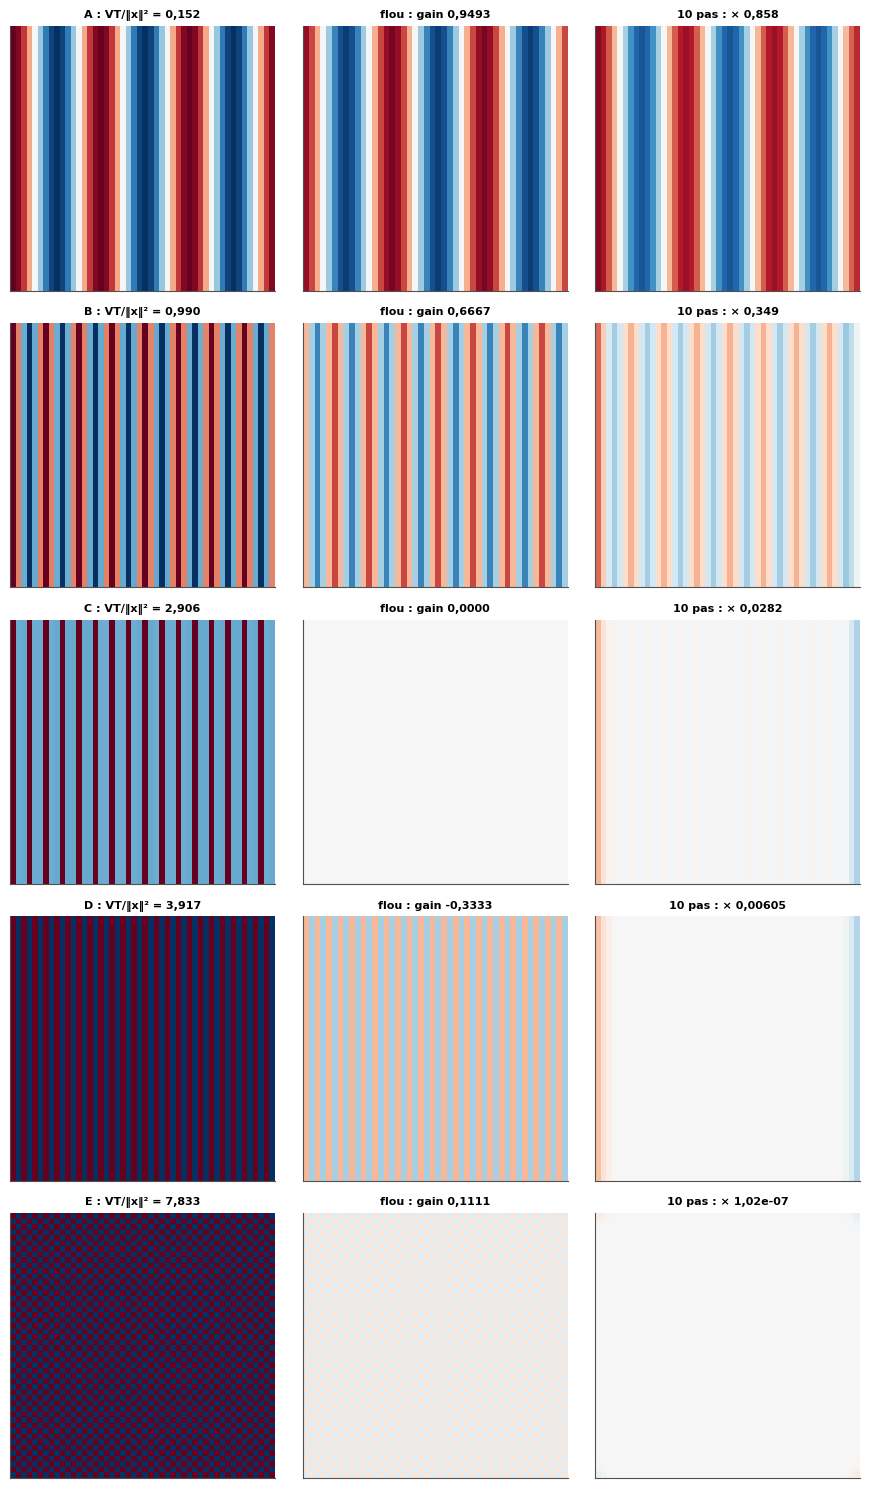

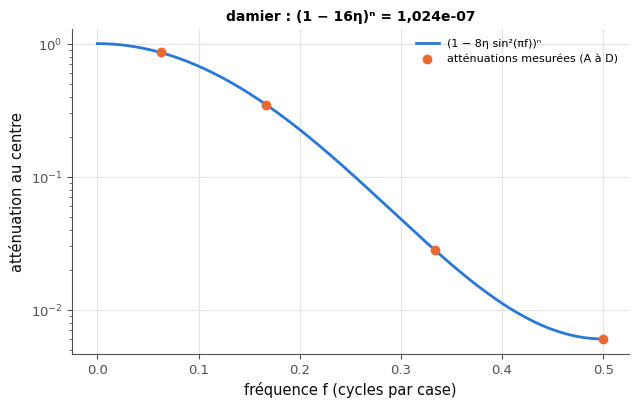

✅ Ex M28.16 : ton laplacien, tes quinze images et ta courbe sont justes.


In [25]:
def grid_laplacian_16(x):
    """L x for the grid x with free edges: in each cell, its number of neighbours times its value, minus the sum of its
    neighbours (no loop over the cells). Returns a new array of the shape of x."""
    x = np.asarray(x, dtype=float)
    Lx = np.zeros_like(x)
    vertical, horizontal = x[1:, :] - x[:-1, :], x[:, 1:] - x[:, :-1]      # the differences between neighbours
    Lx[1:, :] += vertical
    Lx[:-1, :] -= vertical
    Lx[:, 1:] += horizontal
    Lx[:, :-1] -= horizontal
    return Lx


def draw_stripes_16(axes, motifs, eta, n_steps):
    """axes: a (5, 3) grid of axes; motifs: a dict {name: grid}. For each motif (one row of axes): imshow of the motif,
    of its blur (blur3_16) and of the grid after n_steps descent steps x <- x - eta·2Lx, with vmin=-1, vmax=1, and a
    title that gives the value measured. Returns {"ratio": [...], "gain": [...], "decay": [...]} in the order of the
    motifs: xᵀLx/‖x‖², ⟨blur, x_int⟩/‖x_int‖², ‖y_c‖/‖x_c‖ on the block [12:36, 12:36]. No other axes."""
    out = {"ratio": [], "gain": [], "decay": []}
    for k, (name, x) in enumerate(motifs.items()):
        x = np.asarray(x, dtype=float)
        blur, inner = blur3_16(x), x[1:-1, 1:-1]
        y = x.copy()
        for _ in range(n_steps):
            y = y - eta * 2 * grid_laplacian_16(y)
        values = [float((x * grid_laplacian_16(x)).sum() / (x * x).sum()), float((blur * inner).sum() / (inner * inner).sum()),
                  float(np.linalg.norm(y[12:36, 12:36]) / np.linalg.norm(x[12:36, 12:36]))]
        for key, value in zip(out, values):
            out[key].append(value)
        texts = [f"{name} : VT/‖x‖² = {values[0]:.3f}", f"flou : gain {values[1]:.4f}", f"{n_steps} pas : × {values[2]:.3g}"]
        for ax, image, text in zip(axes[k], (x, blur, y), texts):
            ax.imshow(image, cmap="RdBu_r", vmin=-1, vmax=1)
            ax.set_title(text.replace(".", ","), fontsize=8)
            ax.set_xticks([])
            ax.set_yticks([])
    return out


def draw_decay_curve_16(ax, eta, n_steps, freqs, decays):
    """In ax: the curve (1 − 8 eta sin²(πf))**n_steps for f from 0 to 1/2, the points (freqs, decays) with a marker, a
    log scale on the y axis, axis labels, and as title the theoretical value of the checkerboard, (1 − 16 eta)**n_steps.
    No other axes."""
    f = np.linspace(0, 0.5, 201)
    ax.plot(f, (1 - 8 * eta * np.sin(np.pi * f) ** 2) ** n_steps, "-", label="(1 − 8η sin²(πf))ⁿ")
    ax.plot(freqs, decays, "o", label="atténuations mesurées (A à D)")
    ax.set_yscale("log")
    ax.set_xlabel("fréquence f (cycles par case)")
    ax.set_ylabel("atténuation au centre")
    ax.set_title(f"damier : (1 − 16η)ⁿ = {(1 - 16 * eta) ** n_steps:.4g}".replace(".", ","), fontsize=10)
    ax.legend(fontsize=8)


fig_16, axes_16 = plt.subplots(5, 3)
measured_16 = draw_stripes_16(axes_16, MOTIFS_16, ETA_16, STEPS_16)
plt.close(fig_16)
answer_M28_16a, answer_M28_16b = measured_16["ratio"], measured_16["gain"]
answer_M28_16c = np.log10(measured_16["decay"]).tolist()
closed_16 = [4 * math.sin(math.pi * f) ** 2 for f in FREQS_16] + [8.0]
answer_M28_16d = bool(all(r < c for r, c in zip(answer_M28_16a, closed_16)))
theory_16 = [(1 - 8 * ETA_16 * math.sin(math.pi * f) ** 2) ** STEPS_16 for f in FREQS_16] + [(1 - 16 * ETA_16) ** STEPS_16]
answer_M28_16e = bool(np.allclose(measured_16["decay"], theory_16, rtol=1e-9, atol=0))
print("a)", np.round(answer_M28_16a, 4).tolist(), " b)", np.round(answer_M28_16b, 4).tolist())
print("c)", np.round(answer_M28_16c, 3).tolist(), " d)", answer_M28_16d, " e)", answer_M28_16e)

HIDDEN_C16 = {'eta': 0.04,
 'n_steps': 6,
 'ratio': [0.5822120027257839, 1.7269281881521568, 1.9993937387495189, 3.9166666666666665, 2.0906812371280066],
 'gain': [0.804737854124365, 0.4706742197221989, 0.33333333333333337, -0.3333333333333333, 0.40396548564918133],
 'decay': [0.7497771577520788, 0.40143149043579374, 0.35129803161599993, 0.09886748262400001,
           0.3250567416365988]}   # a hidden call: eta, n_steps, and the three lists expected for five hidden motifs (below)
HIDDEN_MOTIFS_C16 = {"H1": np.cos(2 * np.pi * I_16 / 8), "H2": np.cos(2 * np.pi * (I_16 + 2 * J_16) / 10),
                     "H3": np.cos(2 * np.pi * J_16 / 4 + 0.7), "H4": (-1.0) ** I_16,
                     "H5": np.cos(2 * np.pi * (I_16 / 5 - J_16 / 7))}


def tv_c16(x):
    """VT(x) by its definition (fiche §4): the squares of the differences between vertical and horizontal neighbours."""
    return float((np.diff(x, axis=0) ** 2).sum() + (np.diff(x, axis=1) ** 2).sum())


def laplacian_why_c16(rng):
    """'' when grid_laplacian_16 behaves as a laplacian with free edges on random grids, else the reason."""
    for shape in ((5, 7), (6, 4)):
        x, y = rng.normal(size=shape), rng.normal(size=shape)
        x_before = x.copy()
        Lx, Ly, Lxy = (as_floats(grid_laplacian_16(v)) for v in (x, y, x + 2 * y))
        if any(v is None or v.shape != shape for v in (Lx, Ly, Lxy)):
            return f"grid_laplacian_16 doit rendre un tableau de la forme de x, {shape}"
        if not np.array_equal(x, x_before):
            return "grid_laplacian_16 modifie la grille reçue : travaille sur une copie, ou crée un nouveau tableau"
        if not np.allclose(Lxy, Lx + 2 * Ly, atol=1e-9):
            return "L est linéaire : L(x + 2y) doit valoir Lx + 2Ly"
        if math.isclose(float(x.ravel() @ Lx.ravel()), -tv_c16(x), rel_tol=1e-9):
            return "(Lx)_a = deg(a) x_a − la somme des voisines de a, pas l'inverse"
        if abs(float(Lx.sum())) > 1e-9:
            return ("la somme des coefficients de Lx est nulle : en chaque case, son nombre de voisines (2 dans un coin, 3 "
                    "sur un bord, 4 à l'intérieur) fois sa valeur, moins la somme de ses voisines")
        if not math.isclose(float(x.ravel() @ Lx.ravel()), tv_c16(x), rel_tol=1e-9):
            return ("xᵀLx doit valoir VT(x), la somme des carrés des différences entre voisines de la grille : à bords "
                    "libres, la dernière colonne n'est pas voisine de la première (np.roll referme la grille)")
        if not math.isclose(float(y.ravel() @ Lx.ravel()), float(x.ravel() @ Ly.ravel()), rel_tol=1e-9, abs_tol=1e-12):
            return "L est symétrique : ⟨Lx, y⟩ doit valoir ⟨x, Ly⟩"
    return ""


def stripes_why_c16(axes, motifs, result, want=None, letter_check=True):
    """What is wrong in a call of draw_stripes_16 (French phrases): its three lists, then the fifteen images."""
    problems = []
    if not isinstance(result, dict) or set(result) != {"ratio", "gain", "decay"}:
        return [f"draw_stripes_16 doit rendre un dictionnaire de clés \"ratio\", \"gain\", \"decay\", reçu {shown(result)}"]
    lists = {key: as_floats(result[key]) for key in ("ratio", "gain", "decay")}
    if any(v is None or v.shape != (len(motifs),) for v in lists.values()):
        return [f"chaque liste a une valeur par motif, {len(motifs)} en tout, dans l'ordre des motifs"]
    if want is None:                     # the visible call: compared like the answers a) to c) (answers.json)
        for key, letter in (("ratio", "a"), ("gain", "b")):
            if not wbm.check(f"M28.16{letter}", lists[key].tolist(), computed=True, quiet=True).passed:
                problems.append(f"la liste \"{key}\" n'est pas celle qu'attend l'énoncé")
        if np.any(lists["decay"] <= 0) or not wbm.check("M28.16c", np.log10(lists["decay"]).tolist(), computed=True,
                                                        quiet=True).passed:
            problems.append("la liste \"decay\" n'est pas celle qu'attend l'énoncé (‖y_c‖/‖x_c‖ sur le bloc central "
                            "[12:36, 12:36], après les pas de descente)")
    else:
        for key in ("ratio", "gain", "decay"):
            if not np.allclose(lists[key], want[key], rtol=1e-6, atol=1e-9):
                problems.append(f"la liste \"{key}\" n'est pas celle qu'attend l'énoncé pour ces motifs, ce pas et ce "
                                "nombre de pas (dessine les motifs reçus, avec eta et n_steps reçus)")
    for k, (name, x) in enumerate(motifs.items()):
        row = []
        for j in range(3):
            images = axes[k, j].images
            if not images:
                row.append(f"l'image {j + 1} (imshow)")
                continue
            data = np.asarray(images[-1].get_array(), dtype=float)
            if images[-1].get_clim() != (-1.0, 1.0):
                row.append(f"l'échelle de couleurs de −1 à 1 de l'image {j + 1} (vmin=-1, vmax=1)")
            if j == 0 and not matches(data, x):
                row.append("le motif lui-même en première image")
            if j == 1 and not matches(data, blur3_16(x)):
                row.append("son flou (blur3_16) en deuxième image")
            if j == 2 and (data.shape != x.shape or not math.isclose(
                    float(np.linalg.norm(data[12:36, 12:36]) / np.linalg.norm(x[12:36, 12:36])), float(lists["decay"][k]),
                    rel_tol=1e-6, abs_tol=1e-12)):
                row.append("la grille après les pas de descente en troisième image (celle dont \"decay\" est mesuré)")
            value = [lists["ratio"][k], lists["gain"][k], lists["decay"][k]][j]
            candidates = [value] + ([math.log10(value)] if j == 2 and value > 0 else [])
            if not gives(axes[k, j].get_title(), candidates):
                row.append(f"un titre qui donne la valeur mesurée sur l'image {j + 1} (un nombre)")
        if row:
            problems.append(f"motif {name} : il manque " + " ; ".join(row))
    return problems


def curve_why_c16(ax, eta, n_steps, freqs, decays):
    """What is missing in a drawing of draw_decay_curve_16 (French phrases)."""
    missing = []
    if not follows(ax, lambda f: (1 - 8 * eta * np.sin(np.pi * f) ** 2) ** n_steps, 0.0, 0.5):
        missing.append("la courbe (1 − 8η sin²(πf))ⁿ, tracée d'un trait pour f de 0 à 1/2 avec le η et le n reçus")
    if not points_at(ax, freqs, decays, marker_only=True):
        missing.append("les points mesurés (freqs, decays), avec un marqueur")
    if ax.get_yscale() != "log":
        missing.append("l'échelle logarithmique en ordonnée (ax.set_yscale(\"log\"))")
    if not ax.get_xlabel() or not ax.get_ylabel():
        missing.append("des noms d'axes")
    if not gives(ax.get_title(), [(1 - 16 * eta) ** n_steps], rel=0.01, abs_tol=0.0):
        missing.append("en titre, la valeur théorique du damier, (1 − 16η)ⁿ")
    return missing


with checked("M28.16"):
    results_16 = []
    report_16 = reporter(results_16, stop=False)
    why_c16 = laplacian_why_c16(np.random.default_rng())          # random grids, drawn at each run
    report_16(not why_c16, "grid_laplacian_16 : linéaire, symétrique, de somme nulle, et xᵀLx = VT(x) sur deux grilles "
              "tirées au hasard", f"grid_laplacian_16 : {why_c16}")
    fig_16, axes_16 = plt.subplots(5, 3, figsize=(9, 15))
    fig_curve_16, ax_curve_16 = plt.subplots(figsize=(6.5, 4.2))
    try:
        result_16 = []
        opened_16 = drawn(lambda: result_16.append(draw_stripes_16(axes_16, MOTIFS_16, ETA_16, STEPS_16)))
        problems_16 = stripes_why_c16(axes_16, MOTIFS_16, result_16[0])
        report_16(not problems_16, "draw_stripes_16 (η = 0,05, 10 pas) : les trois listes comme attendu, et les quinze "
                  "images, leur échelle et leurs titres", "draw_stripes_16 : " + " ; ".join(problems_16))
        fig_c16, axes_c16 = plt.subplots(5, 3)
        try:
            hidden_c16 = []
            opened_16 += drawn(lambda: hidden_c16.append(draw_stripes_16(axes_c16, HIDDEN_MOTIFS_C16, HIDDEN_C16["eta"],
                                                                          HIDDEN_C16["n_steps"])))
            problems_c16 = stripes_why_c16(axes_c16, HIDDEN_MOTIFS_C16, hidden_c16[0], want=HIDDEN_C16)
        finally:
            plt.close(fig_c16)
        report_16(not problems_c16, "un appel caché de draw_stripes_16 (cinq autres motifs, un autre pas, un autre nombre "
                  "de pas) est juste aussi", "un appel caché de draw_stripes_16 : " + " ; ".join(problems_c16))
        decays_16 = as_floats(result_16[0].get("decay")) if isinstance(result_16[0], dict) else None
        decays_16 = decays_16[:4] if decays_16 is not None and decays_16.shape == (5,) else np.array([0.8, 0.3, 0.03, 0.006])
        opened_16 += drawn(draw_decay_curve_16, ax_curve_16, ETA_16, STEPS_16, FREQS_16, decays_16)
        missing_16 = curve_why_c16(ax_curve_16, ETA_16, STEPS_16, FREQS_16, decays_16)
        report_16(not missing_16, "draw_decay_curve_16 : la courbe, les points, l'échelle logarithmique, les noms d'axes et "
                  "le titre", "draw_decay_curve_16 : il manque " + " ; ".join(missing_16))
        fig_c16, ax_c16 = plt.subplots()
        try:
            opened_16 += drawn(draw_decay_curve_16, ax_c16, 0.03, 8, [0.1, 0.25, 0.4], [0.8, 0.45, 0.15])
            missing_c16 = curve_why_c16(ax_c16, 0.03, 8, [0.1, 0.25, 0.4], [0.8, 0.45, 0.15])
        finally:
            plt.close(fig_c16)
        report_16(not missing_c16, "un appel caché de draw_decay_curve_16 (η = 0,03, 8 pas, trois autres points) est juste "
                  "aussi", "un appel caché de draw_decay_curve_16 (η = 0,03, 8 pas) : il manque " + " ; ".join(missing_c16))
        report_16(not opened_16, "tes deux fonctions dessinent dans les axes reçus",
                  "tes fonctions doivent dessiner dans les axes reçus, sans ouvrir de figure")
    except BaseException:
        plt.close(fig_16)
        plt.close(fig_curve_16)
        raise
    fig_16.tight_layout()
    fig_curve_16.tight_layout()
    plt.show()
    verdict("M28.16", all(results_16), "ton laplacien, tes quinze images et ta courbe sont justes.",
            "relis les lignes ❌ ci-dessus.")

In [26]:
from scipy.signal import convolve2d as convolve2d_16r


def path_laplacian_16r(n):
    """The laplacian of a path of n cells (free ends)."""
    return np.diag([1.0] + [2.0] * (n - 2) + [1.0]) - np.eye(n, k=1) - np.eye(n, k=-1)


L_16r = np.kron(path_laplacian_16r(48), np.eye(48)) + np.kron(np.eye(48), path_laplacian_16r(48))   # the grid, row-major
i_16r, j_16r = np.meshgrid(np.arange(48), np.arange(48), indexing="ij")
motifs_16r = [np.cos(2 * np.pi * j_16r / 16), np.cos(2 * np.pi * j_16r / 6), np.cos(2 * np.pi * j_16r / 3),
              np.cos(np.pi * j_16r), np.cos(np.pi * (i_16r + j_16r))]


def descent_16r(v, eta, n_steps):
    """n_steps descent steps v <- v - eta (2 L) v (dense matrix L of the grid)."""
    for _ in range(n_steps):
        v = v - eta * (2 * L_16r @ v)
    return v


ratios_16r, gains_16r, decays_16r = [], [], []
for x_16r in motifs_16r:
    v = x_16r.ravel()
    ratios_16r.append(float(v @ L_16r @ v / (v @ v)))
    blur = convolve2d_16r(x_16r, np.ones((3, 3)) / 9, mode="valid")
    inner = x_16r[1:-1, 1:-1]
    gains_16r.append(float((blur * inner).sum() / (inner * inner).sum()))
    y = descent_16r(v, 0.05, 10).reshape(48, 48)
    decays_16r.append(float(np.linalg.norm(y[12:36, 12:36]) / np.linalg.norm(x_16r[12:36, 12:36])))
closed_16r = [4 * math.sin(math.pi / p) ** 2 for p in (16, 6, 3, 2)] + [8.0]
wbm.record("M28.16a", ratios_16r, decimals=5,
           mistakes={"sur une grille à bords libres, une case du bord a moins de quatre voisines : le rapport de la grille "
                     "refermée n'est qu'approché": closed_16r,
                     "le rapport est VT(x)/‖x‖² : divise par la somme des carrés des valeurs du motif, pas par le "
                     "nombre de cases": [float(x.ravel() @ L_16r @ x.ravel() / x.size) for x in motifs_16r]})
wbm.record("M28.16b", gains_16r, decimals=6,
           mistakes={"le gain se mesure sur les cases intérieures : ⟨flou, x_int⟩/‖x_int‖²":
                         [float((convolve2d_16r(x, np.ones((3, 3)) / 9, mode="valid") * x[1:-1, 1:-1]).sum() / (x * x).sum())
                          for x in motifs_16r]})
wbm.record("M28.16c", np.log10(decays_16r).tolist(), decimals=7,
           mistakes={"le logarithme décimal, log10, pas le logarithme népérien": np.log(decays_16r).tolist(),
                     "un pas de descente sur VT est x ← x − η·2Lx (le gradient de xᵀLx est 2Lx)":
                         [float(np.log10(np.linalg.norm(descent_16r(x.ravel(), 0.05 / 2, 10).reshape(48, 48)[12:36, 12:36])
                                         / np.linalg.norm(x[12:36, 12:36]))) for x in motifs_16r]})
wbm.record("M28.16d", bool(all(r < c for r, c in zip(ratios_16r, closed_16r))),
           mistakes={"compare chaque rapport mesuré à 4 sin²(πf), et le damier à 8": False})
theory_16r = [(1 - 8 * 0.05 * math.sin(math.pi / p) ** 2) ** 10 for p in (16, 6, 3, 2)] + [(1 - 16 * 0.05) ** 10]
wbm.record("M28.16e", bool(np.allclose(decays_16r, theory_16r, rtol=1e-9, atol=0)),
           mistakes={"au centre, une case à plus de 10 cases du bord n'a pas encore « vu » le bord : compare tes atténuations "
                     "aux valeurs de la courbe": False})

WBM_ANSWER {"decimals": 5, "element_coarse": [["9202a4d0c64b8739528a1955ef167b4de5b4592f98e57305ac6f678cd3a7c133"], ["75861c98aaee93c638721dedaa5ff2728764689124e0f3554b05bae355bca910"], ["4a6b016294de94935de76cc43060a452e0dc0958799dae39be49d1ab9fbf998b", "cc10e5e0b7a24aab6e29b1b0478d089f33edd0fa7568e2394f200ef7977847fe"], ["13cd0e1f3f45edac98c8bbd5660aae208a9b82891be48b746cd516470cb2bc6d"], ["3e5da788c2cfd8f021582d00f2d47f808e9a442892a40bb56d1626317eb875fe"]], "element_coarse_any": [["c87663b5c1e484388cbbc8ab15b9798e8d8e690d02724b494ac8e5f10d175497", "89a037d8a5290657d47c6c660a86f5c027bc1eb19867d81e2025fca9fb365bff", "0653f1ae7743a24e158ae56795f58de3f31ee2640aa6c2b5be8711972f9d307a"], ["e426b577e19bf00a34b20511197d7f93b452923bfdc9cae3b13bf0d7c57dd690", "59a9a01f1aec353694cc0bb1eb179de3165fdf6342aef20dcfa5d4b2d79451ea", "b68dc2cdef8d8661f1076ab78c8cd284d2776313e2220e199c632de93de439d9", "ca30dda1aa2bcb0ed699b5f9c2b73fc59d36073384835c47d70ad92c9482a86e"], ["64434e0d904c7530d43a3f0397acf3

WBM_ANSWER {"array_rounded": {"1": "fddbc1119fdcf99298d0ad6df30e905ec92cfe945e6760ae2a5d85d0d667a15e", "2": "bff5af919ec2974497f956dcea5d85702e09ba471b071b1910faccdcc58730fe", "3": "7481859a1c37e25481b47b49fc64727e1c7062b7b9afc05fdc71f2e1272696d7", "4": "96eb879c855edace323f93feebb7538c62c2915277ed76eb53329c0f4d243e98", "5": "d464ac479bd6e83f5478b142bb1ddb6a922f2d98944e415e12cfda3dd8b22a38"}, "decimals": 7, "element_coarse": [["77d9d961bb03eeae82f821f3baab9f8e4bf83ec275c382a45ea3e9458bad3f10"], ["d52da2cfcfb21edfa5988dddf7bdeba3f5ecd6608dd1a1438e825faab298c44e"], ["c286cbc94297e8c7557f3f15e73ebb29d2cc9a0b13497da950b7fdbeb153547f"], ["cba24f9778da9fb9f8fe25d6ad22c04ffe4d0b84aba30d9e56d02b5e2942703f"], ["c03e19489c03f86da38bd8e9a5495edd83a2e826ede12cfd2428b1422dc26c00"]], "element_coarse_any": [["83a6df827721097cf075ee35aaf1e7494862c77235e53cd6a8f452c354d2f89b", "3f8126579a49d743e778ed63937b566b21d5731d57416f2ca59913b0c1184bf6", "be18553832d5d7971a665c7405a71bb19774c782c524452e850ea7804e

**Après les figures**, dans ta copie : pourquoi le flou efface-t-il exactement C et pas D ? Pourquoi les rapports de la grille à bords libres sont-ils un peu sous ceux de la grille refermée ? Que deviendrait l'atténuation au centre avec 30 pas ?

💡 a) $0{,}152$ ; $0{,}990$ ; $2{,}906$ ; $3{,}917$ ; $7{,}833$ (sur une grille refermée : 0,152 ; 1 ; 3 ; 4 ; 8). b) $0{,}9493$ ; $0{,}6667$ ; $0$ ; $-0{,}3333$ ; $0{,}1111$. c) $-0{,}07$ ; $-0{,}46$ ; $-1{,}55$ ; $-2{,}22$ ; $-6{,}99$. d) Vrai. e) Vrai : sur le bloc central, $0{,}9^{10}$, $0{,}7^{10}$, $0{,}6^{10}$ et $0{,}2^{10}$ pour B, C, D et le damier.

## Partie C · Déboguer, tester

Fiche §2, §3 et §6. Trois erreurs classiques, qui passent une vérification mal choisie ; un test de propriété de `points_from_gram`. Les versions fausses et le code du collègue s'appuient sur la référence (`ref_sampling`), pour ne pas dépendre de ton code.

### Ex M28.17 — Chasse à l'erreur : un double centrage fait sur les distances au lieu de leurs carrés, une montée qui coupe le gradient au lieu du point, une prépériode comptée dans la période 🐛 ★ ⏱️ 20 min
**Objectif :** reconnaître trois erreurs classiques sur le double centrage, la montée projetée et la période, qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §2, §3 et §6 ; Ex M28.2, M28.3 et M28.7 · **Parcours :** C, E

Un collègue a écrit trois fonctions, chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `map_from_distances(D, dim=2)` doit rendre une carte (une ligne par lieu) dont les distances sont celles de la matrice `D` ; elle forme $\mathbf{J}$, calcule `G = -0.5 * J @ D @ J`, puis rend `points_from_gram(G, dim)`. Il l'a vérifiée sur un triangle équilatéral de côté 1 : les trois distances de la carte valent 1.
2. `tune_emitters(x0, grad, eta=0.05, n_steps=120, lower=0.0, upper=1.0)` doit faire `n_steps` pas de montée projetée sur le pavé $[\texttt{lower}, \texttt{upper}]^n$, le gradient étant donné par la fonction `grad` ; elle répète `x = x + eta * np.clip(grad(x), lower, upper)`. Il l'a vérifiée sur $f(\mathbf{x}) = -\lVert\mathbf{x} - \mathbf{c}\rVert^2$ avec $\mathbf{c} = (0{,}45 ;\ 0{,}62 ;\ 0{,}88)$, depuis $(0{,}15 ;\ 0{,}25 ;\ 0{,}05)$, avec les réglages par défaut : la montée arrive en $\mathbf{c}$, à $10^{-5}$ près, à l'intérieur du pavé $[0, 1]^3$.
3. `cycle_of(f, x0)` doit rendre `(mu, lam)`, la prépériode et la période de la suite $u_{t+1} = f(u_t)$ ; elle note dans un dictionnaire l'indice où chaque valeur apparaît, et, à la première valeur déjà vue, d'indice $j$, rend l'indice $i$ de sa première apparition et `j`. Il l'a vérifiée sur $x \mapsto (x + 3) \bmod 10$ depuis 0 : `(0, 10)`.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `map_from_distances_fixed`, `tune_emitters_fixed` et `cycle_of_fixed`, avec les mêmes arguments. Puis réponds :
- a) pour le losange de M28.2 (`D_RHOMBUS`), les distances AB, AC et BD de la carte de `map_from_distances_fixed`, puis de celle de `map_from_distances` (une liste de 6 nombres) ;
- b) pour quatre émetteurs, $f(\mathbf{x}) = -\lVert\mathbf{x} - \mathbf{c}\rVert^2$ avec $\mathbf{c} = (1{,}3 ;\ -0{,}2 ;\ 0{,}6 ;\ 0{,}35)$, depuis $\mathbf{x}_0 = (0{,}2 ;\ 0{,}7 ;\ 0{,}78 ;\ 0{,}1)$, avec les réglages par défaut : le réglage final de `tune_emitters_fixed`, puis celui de `tune_emitters` (une liste de 8 nombres) ;
- c) pour le générateur jouet $x \mapsto (x^2 + 3) \bmod 22$, depuis 2 : `cycle_of_fixed`, puis `cycle_of` (une liste de 4 entiers).

Dans ta copie : pour chacune des trois erreurs, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas cachés : des nuages de points qui ne sont pas des triangles équilatéraux, des montées sur d'autres pavés dont le maximum n'est pas à l'intérieur, des suites avec une prépériode.

In [27]:
# The colleague's code
def map_from_distances(D, dim=2):
    """A map (one row per place) whose distances are those of the matrix D."""
    D = np.asarray(D, dtype=float)
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    G = -0.5 * J @ D @ J
    return ref_sampling.points_from_gram(G, dim)


def tune_emitters(x0, grad, eta=0.05, n_steps=120, lower=0.0, upper=1.0):
    """n_steps steps of projected gradient ascent on the box [lower, upper]^n; grad(x) gives the gradient."""
    x = np.array(x0, dtype=float)
    for _ in range(n_steps):
        x = x + eta * np.clip(grad(x), lower, upper)
    return x


def cycle_of(f, x0):
    """(mu, lam): the preperiod and the period of the sequence u_(t+1) = f(u_t), from u_0 = x0."""
    seen, x, t = {}, x0, 0
    while x not in seen:
        seen[x] = t
        x, t = f(x), t + 1
    return seen[x], t


# The colleague's checks: all pass
triangle_17 = np.array([[0.0, 1, 1], [1, 0, 1], [1, 1, 0]])
map_check_17 = map_from_distances(triangle_17)
print("(1)", np.round(np.sqrt(((map_check_17[:, None] - map_check_17[None]) ** 2).sum(-1)), 6).tolist(),
      "(attendu des 1 hors de la diagonale)")
c_check_17 = np.array([0.45, 0.62, 0.88])
x_check_17 = tune_emitters(np.array([0.15, 0.25, 0.05]), lambda x: -2.0 * (x - c_check_17))
print("(2)", bool(np.allclose(x_check_17, c_check_17, atol=1e-5)), bool(np.all((0 <= x_check_17) & (x_check_17 <= 1))),
      "(attendu True, True)")
print("(3)", cycle_of(lambda x: (x + 3) % 10, 0), "(attendu (0, 10))")

(1) [[0.0, 1.0, 1.0], [1.0, 0.0, 1.0], [1.0, 1.0, 0.0]] (attendu des 1 hors de la diagonale)
(2) True True (attendu True, True)
(3) (0, 10) (attendu (0, 10))


In [28]:
def map_from_distances_fixed(D, dim=2):
    """A map (one row per place) whose distances are those of the matrix D."""
    D = np.asarray(D, dtype=float)
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    G = -0.5 * J @ (D ** 2) @ J                     # the double centering of the SQUARED distances
    return mymath.sampling.points_from_gram(G, dim)


def tune_emitters_fixed(x0, grad, eta=0.05, n_steps=120, lower=0.0, upper=1.0):
    """n_steps steps of projected gradient ascent on the box [lower, upper]^n; grad(x) gives the gradient."""
    x = np.array(x0, dtype=float)
    for _ in range(n_steps):
        x = np.clip(x + eta * grad(x), lower, upper)  # the step, then the projection of the POINT
    return x


def cycle_of_fixed(f, x0):
    """(mu, lam): the preperiod and the period of the sequence u_(t+1) = f(u_t), from u_0 = x0."""
    seen, x, t = {}, x0, 0
    while x not in seen:
        seen[x] = t
        x, t = f(x), t + 1
    return seen[x], t - seen[x]                     # the length of the cycle, without the tail


def three_distances_17(Z):
    """AB, AC and BD of a map of the rhombus."""
    Z = np.asarray(Z, dtype=float)
    return [float(np.linalg.norm(Z[a] - Z[b])) for a, b in ((0, 1), (0, 2), (1, 3))]


answer_M28_17a = three_distances_17(map_from_distances_fixed(D_RHOMBUS)) + three_distances_17(map_from_distances(D_RHOMBUS))
c_17 = np.array([1.3, -0.2, 0.6, 0.35])
x0_17 = np.array([0.2, 0.7, 0.78, 0.1])
answer_M28_17b = (tune_emitters_fixed(x0_17, lambda x: -2.0 * (x - c_17)).tolist()
                  + tune_emitters(x0_17, lambda x: -2.0 * (x - c_17)).tolist())
toy_17 = lambda x: (x * x + 3) % 22           # noqa: E731
answer_M28_17c = list(cycle_of_fixed(toy_17, 2)) + list(cycle_of(toy_17, 2))
print("a)", np.round(answer_M28_17a, 4).tolist(), " b)", np.round(answer_M28_17b, 6).tolist(), " c)", answer_M28_17c)

CASES_C17 = {'maps': [{'points': [[-9.57, -0.74], [-7.27, 8.52], [8.8, -0.6], [7.53, -9.0], [-3.34, -7.2], [6.82, 7.82],
                      [8.68, 5.17]],
           'dim': 2},
          {'points': [[-2.62, 1.46, -2.5], [-1.73, 1.73, 5.01], [5.18, 2.97, 2.69], [3.58, -0.07, -3.4],
                      [5.72, 1.11, -4.3], [-1.18, -1.74, 2.08]],
           'dim': 3}],
 'emitters': [{'A': [[2.0, 0.8, 0.0], [0.8, 1.5, 0.5], [0.0, 0.5, 1.0]],
               'c': [1.6, -0.9, 0.7],
               'x0': [0.1, 0.4, 0.9],
               'eta': 0.05,
               'n_steps': 400,
               'lower': -0.5,
               'upper': 1.2},
              {'A': [[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]],
               'c': [-0.3, 1.25, 0.45, 0.8],
               'x0': [0.8, 0.1, 0.9, 0.2],
               'eta': 0.05,
               'n_steps': 200,
               'lower': 0.0,
               'upper': 1.0}],
 'cycles': [{'map': 'squares', 'x0': 3, 'mu': 5, 'lam': 2}, {'map': 'affine', 'x0': 2, 'mu': 3, 'lam': 5},
            {'map': 'automaton', 'x0': (1, 3), 'mu': 6, 'lam': 4}]}   # the hidden cases of the three corrected functions
CYCLES_C17 = {"squares": lambda x: (x * x + 5) % 26, "affine": lambda x: (6 * x + 1) % 40,
              "automaton": lambda s: (s[1], (s[0] * s[1] + 2) % 7)}       # the maps of the hidden sequences

results_17, parts_17 = [], []


def report_17(ok, success, failure):
    results_17.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_17(part, name, function, *args, **kwargs):
    """function(*args, **kwargs); an error of the learner's code becomes one ❌ line that names the function (the check of
    this part stops there, the final verdict stays)."""
    try:
        return function(*args, **kwargs)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        hint = ""
        if part == 1 and isinstance(exc, ValueError) and "semi-definite" in str(exc):
            hint = (" ; −½ J D J, fait sur les distances, n'est en général pas une matrice de Gram : le double centrage "
                    "se fait sur leurs carrés")
        report_17(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:160]}{hint}")
        parts_17.append(part)
        raise StopCheck from None


with checked("M28.17"):                                       # (1) map_from_distances_fixed
    wrong_17 = []
    for case_c17 in CASES_C17["maps"]:
        points_c17 = np.array(case_c17["points"])
        D_c17 = np.sqrt(sq_dists_of(points_c17))
        before_c17 = D_c17.copy()
        got_c17 = call_17(1, "map_from_distances_fixed", map_from_distances_fixed, D_c17, case_c17["dim"])
        arr_c17 = as_floats(got_c17)
        shape_c17 = (len(points_c17), case_c17["dim"])
        if arr_c17 is None or arr_c17.shape != shape_c17:
            wrong_17.append(f"attendu une carte de forme {shape_c17} (une ligne par lieu, dim colonnes), reçu "
                            f"{None if arr_c17 is None else arr_c17.shape}")
            continue
        if not np.array_equal(D_c17, before_c17):
            wrong_17.append("ta fonction modifie la matrice D reçue : travaille sur une copie")
            continue
        d_c17, tol_c17 = np.sqrt(sq_dists_of(arr_c17)), 1e-7 * D_c17.max()
        if np.allclose(d_c17, D_c17, rtol=1e-7, atol=tol_c17):
            continue
        if np.allclose(d_c17, math.sqrt(2) * D_c17, rtol=1e-7, atol=tol_c17):
            wrong_17.append("G = −½ J D⁽²⁾ J : sans le facteur −½, chaque distance est multipliée par √2")
        else:
            wrong_17.append(f"{len(points_c17)} lieux dans un espace de dimension {case_c17['dim']} : les distances de ta "
                            "carte ne sont pas celles de D (le double centrage se fait sur les carrés des distances, "
                            "coefficient par coefficient)")
    report_17(not wrong_17, "(1) map_from_distances_fixed : deux nuages cachés, dans le plan et dans l'espace",
              "(1) map_from_distances_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(1)

with checked("M28.17"):                                       # (2) tune_emitters_fixed
    wrong_17 = []
    for case_c17 in CASES_C17["emitters"]:
        A_c17, c_c17 = np.array(case_c17["A"]), np.array(case_c17["c"])
        lower_c17, upper_c17 = case_c17["lower"], case_c17["upper"]

        def grad_c17(x, A=A_c17, c=c_c17):
            return -2.0 * A @ (np.asarray(x, dtype=float) - c)

        got_c17 = call_17(2, "tune_emitters_fixed", tune_emitters_fixed, np.array(case_c17["x0"]), grad_c17,
                          eta=case_c17["eta"], n_steps=case_c17["n_steps"], lower=lower_c17, upper=upper_c17)
        x_c17 = as_floats(got_c17)
        if x_c17 is None or x_c17.shape != c_c17.shape:
            wrong_17.append(f"attendu le réglage final, un tableau de forme {c_c17.shape}, reçu {shown(got_c17)}")
            continue
        if np.any(x_c17 < lower_c17 - 1e-12) or np.any(x_c17 > upper_c17 + 1e-12):
            wrong_17.append(f"le réglage final sort du pavé [{fr(lower_c17, 1)} ; {fr(upper_c17, 1)}] : projette le point "
                            "(np.clip) après chaque pas, avec les bornes lower et upper reçues")
            continue
        g_c17 = grad_c17(x_c17)
        at_low, at_up = x_c17 <= lower_c17 + 1e-9, x_c17 >= upper_c17 - 1e-9     # the optimality conditions on a box
        if np.all(np.abs(g_c17[~at_low & ~at_up]) <= 1e-6) and np.all(g_c17[at_low] <= 1e-6) and np.all(g_c17[at_up] >= -1e-6):
            continue
        if np.allclose(x_c17, np.clip(c_c17, lower_c17, upper_c17), atol=1e-6):
            wrong_17.append("projeter seulement à la fin donne la projection du maximum sans contrainte, qui n'est pas le "
                            "maximum sur le pavé quand l'énergie a des termes croisés : projette le point après chaque pas")
        elif np.any((g_c17 < -1e-6) & ~at_low):
            wrong_17.append("une coordonnée dont le gradient est négatif reste au-dessus de sa borne : elle doit pouvoir "
                            "baisser (on ne coupe pas le gradient, on projette le point)")
        else:
            wrong_17.append("la montée projetée s'arrête là où aucun pas permis ne fait plus monter f, ce qui n'est pas le "
                            "cas ici : projette le point après chaque pas, pas seulement à la fin")
    report_17(not wrong_17, "(2) tune_emitters_fixed : deux montées cachées, sur d'autres pavés, dont une énergie à "
              "termes croisés", "(2) tune_emitters_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(2)

with checked("M28.17"):                                       # (3) cycle_of_fixed
    wrong_17 = []
    for case_c17 in CASES_C17["cycles"]:
        got_c17 = call_17(3, "cycle_of_fixed", cycle_of_fixed, CYCLES_C17[case_c17["map"]], case_c17["x0"])
        try:
            mu_c17, lam_c17 = (int(v) for v in got_c17)
        except (TypeError, ValueError):
            wrong_17.append(f"cycle_of_fixed doit rendre le couple (mu, lam), reçu {shown(got_c17)}")
            continue
        if (mu_c17, lam_c17) == (case_c17["mu"], case_c17["lam"]):
            continue
        if (mu_c17, lam_c17) == (case_c17["mu"], case_c17["mu"] + case_c17["lam"]):
            wrong_17.append("tu rends encore l'indice de la première répétition : la période est la longueur du cycle, "
                            "sans la queue")
        elif (mu_c17, lam_c17) == (case_c17["lam"], case_c17["mu"]):
            wrong_17.append("cycle_of_fixed rend (mu, lam) : la prépériode, puis la période")
        else:
            wrong_17.append("une suite cachée avec une prépériode : ton couple (mu, lam) n'est pas le bon (mu est l'indice "
                            "de la première apparition de la valeur répétée)")
    report_17(not wrong_17, "(3) cycle_of_fixed : trois suites cachées avec une prépériode, dont une sur des couples",
              "(3) cycle_of_fixed : " + " ; ".join(list(dict.fromkeys(wrong_17))[:2]))
    parts_17.append(3)

if len(set(parts_17)) == 3:
    verdict("M28.17", all(results_17), "les trois fonctions corrigées passent tous les cas.", "relis les lignes ❌ ci-dessus.")

a) [29.0, 40.0, 42.0, 4.5277, 6.3246, 6.4807]  b) [1.0, 0.0, 0.600001, 0.349999, 1.299994, 0.7, 0.78, 0.349999]  c) [2, 6, 2, 8]
✅ (1) map_from_distances_fixed : deux nuages cachés, dans le plan et dans l'espace
✅ (2) tune_emitters_fixed : deux montées cachées, sur d'autres pavés, dont une énergie à termes croisés
✅ (3) cycle_of_fixed : trois suites cachées avec une prépériode, dont une sur des couples
✅ Ex M28.17 : les trois fonctions corrigées passent tous les cas.


In [29]:
from scipy import linalg as linalg_17r


def map_17r(G, dim):
    """The oracle: the dim columns √λ_k q_k of the largest eigenvalues (scipy.linalg.eigh); the signs do not matter here."""
    w, V = linalg_17r.eigh(G)
    return V[:, ::-1][:, :dim] * np.sqrt(w[::-1][:dim])


def dists_17r(Z):
    return [float(math.dist(Z[a], Z[b])) for a, b in ((0, 1), (0, 2), (1, 3))]


D_17r = np.array([[0.0, 29, 40, 29], [29, 0, 29, 42], [40, 29, 0, 29], [29, 42, 29, 0]])
J_17r = np.eye(4) - 0.25
right_17r = dists_17r(map_17r(-0.5 * J_17r @ D_17r ** 2 @ J_17r, 2))
wrong_17r = dists_17r(map_17r(-0.5 * J_17r @ D_17r @ J_17r, 2))
wbm.record("M28.17a", right_17r + wrong_17r, decimals=6,
           mistakes={"map_from_distances_fixed fait encore le double centrage sur les distances, pas sur leurs carrés":
                         wrong_17r + wrong_17r,
                     "les trois dernières distances sont celles de la version FAUSSE, map_from_distances":
                         right_17r + right_17r})


def ascent_17r(clip_point, clip_gradient, c=(1.3, -0.2, 0.6, 0.35), x0=(0.2, 0.7, 0.78, 0.1), eta=0.05, n_steps=120):
    """The oracle: the 120 steps written again with Python floats, the point and/or the gradient clipped to [0, 1]."""
    x = list(x0)
    for _ in range(n_steps):
        g = [-2.0 * (xk - ck) for xk, ck in zip(x, c)]
        if clip_gradient:
            g = [min(max(gk, 0.0), 1.0) for gk in g]
        x = [xk + eta * gk for xk, gk in zip(x, g)]
        if clip_point:
            x = [min(max(xk, 0.0), 1.0) for xk in x]
    return x


fixed_17r, colleague_17r = ascent_17r(True, False), ascent_17r(False, True)
wbm.record("M28.17b", fixed_17r + colleague_17r, decimals=6,
           mistakes={"couper aussi le gradient empêche une coordonnée de gradient négatif de baisser : on ne coupe que le "
                     "point": ascent_17r(True, True) + colleague_17r,
                     "les quatre derniers nombres sont ceux de la version FAUSSE, tune_emitters": fixed_17r + fixed_17r})


def rho_17r(f, x0):
    seen, x, t = {}, x0, 0
    while x not in seen:
        seen[x] = t
        x, t = f(x), t + 1
    return seen[x], t - seen[x], t


mu_17r, lam_17r, j_17r = rho_17r(lambda x: (x * x + 3) % 22, 2)
wbm.record("M28.17c", [mu_17r, lam_17r, mu_17r, j_17r],
           mistakes={"cycle_of_fixed rend encore l'indice de la première répétition : la période est j − i":
                         [mu_17r, j_17r, mu_17r, j_17r],
                     "les deux derniers nombres sont ceux de la version FAUSSE, cycle_of": [mu_17r, lam_17r, mu_17r, lam_17r],
                     "cycle_of_fixed rend (mu, lam) : la prépériode, puis la période": [lam_17r, mu_17r, mu_17r, j_17r]})

WBM_ANSWER {"array_rounded": {"1": "dc679bbaa6c05c4084716ec67af4c52e07eb3f2a6ffb4bb1c9e4fcfb753ecfad", "2": "ad2e158fa0d5b60190f5fd1ea7f875bc2e2fce709113e3ad6ba6fa4324210597", "3": "898d74da4a548c3eb5a589e5ba76c1444eb6b4796b658cb4a192051a2e7ed18f", "4": "deedb85d0931eeaf508e072d58a15bbb8994f6450c861b9fd5b675902feb6b39", "5": "c27d55b5268e4a80aa453508bd94ede5f974fdd0cd336acc6ac50175e36a1e38"}, "decimals": 6, "element_coarse": [["b96af999c853f2f5d9e0a71e4167d7684f313c7f09e971783b1b900e6a261468"], ["f221ebe406b5de37018bd08c5f97fc6386b4f7aa03ee8942a46475847ef51403"], ["1a6bb8327dc5ab5f04c5ab445f0e2c07b41377b0bf6296a4b9315eb6bbd419d2"], ["86157a47ee8f1782876a38bd9be7a4bf1fd32bbf0f585f6c422f5de8c6337437"], ["fd54c800195df8583a5a5904cdef1db6c705e231e1c6e10ae12c07b186d1bc48"], ["d3bd5e0cd3942ca54d736aa959fb3bcf08cb1f9621f28a7f1585b878b955b026"]], "element_coarse_any": [["bae7b41e3e371a8a36c098503451c1110c0e2dd6f303f1c547054979ba0f8aef", "b1bcc4fbc7a8896176b92d809c070b90d2e0c01a51fecae31430eb8c

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas, et quelle vérification l'aurait vue ?

💡 (1) `map_from_distances` fait le double centrage sur les distances : sur un triangle de côté 1, $d = d^2$. Correction : `G = -0.5 * J @ (D ** 2) @ J`. a) 29, 40, 42 ; puis environ 4,53 ; 6,32 ; 6,48. (2) `tune_emitters` coupe le gradient au lieu du point : la vérification partait sous $\mathbf{c}$, intérieur au pavé, avec des gradients entre 0 et 1,66. Correction : `x = np.clip(x + eta * grad(x), lower, upper)`. b) $(1, 0, 0{,}6, 0{,}35)$ ; puis $(1{,}3 ;\ 0{,}7 ;\ 0{,}78 ;\ 0{,}35)$, hors du pavé. (3) `cycle_of` rend l'indice $j$ de la première répétition : sur une bijection, $\mu = 0$ et $j = \lambda$. Correction : `return seen[x], t - seen[x]`. c) `[2, 6, 2, 8]`.

### Ex M28.18 — Un test de propriété : la configuration rendue redonne la matrice de Gram et les distances, pour des points tirés au hasard 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété à tolérance relative, qui compte ses échecs sur des nuages tirés au hasard, et voir ce qu'il attrape et ce qu'il ne peut pas attraper.  
**Prérequis :** fiche §2 ; Ex M28.13 · **Parcours :** C

Écris `gram_property_test_18(n_trials, rng, func=None, rtol=1e-9)` ; quand `func` vaut `None`, le test prend `mymath.sampling.points_from_gram` **au moment de l'appel**. Pour chacun des `n_trials` essais, dans cet ordre : `n = int(rng.integers(2, 9))`, `d = int(rng.integers(1, 5))`, `scale = 10.0 ** rng.uniform(-2, 3)`, `P = scale * rng.standard_normal((n, d))`, puis, si `rng.random() < 0.3`, `P[-1] = P[0]` (un point répété), puis `t = scale * rng.standard_normal(d)` ; ensuite `G = P @ P.T`, $s = \max(1, \max\lvert G_{ij}\rvert)$ et `X = func(G)`. La fonction rend un dictionnaire de quatre compteurs d'essais (un essai compte une fois s'il échoue) :
- `"shape"` : `X` n'a pas la forme $(n, r)$, avec $r$ le rang de `P` (`np.linalg.matrix_rank`), ou contient un nombre non fini ;
- `"gram"` : $\max\lvert\mathbf{X}\mathbf{X}^\top - \mathbf{G}\rvert > \texttt{rtol}\cdot s$ (ou `X` non fini) ;
- `"distances"` : les carrés des distances des lignes de `X` s'écartent de ceux de `P` de plus de $4\,\texttt{rtol}\cdot s$ (ou `X` non fini) ;
- `"translation"` : la carte `func(Gc)` de la matrice doublement centrée `Gc` $= -\frac12\mathbf{J}\mathbf{D}^{(2)}\mathbf{J}$ des points translatés `P + t` a des carrés de distances qui s'écartent de ceux de `P` de plus de $4\,\texttt{rtol}\cdot\max(1, \max\lvert(\mathbf{G}_c)_{ij}\rvert)$ (ou n'est pas finie).

Les carrés des distances se calculent dans le test, avec NumPy, sans appeler `mymath`. La cellule fournie donne cinq versions fausses de `points_from_gram` : `no_sqrt` (les colonnes $\lambda_k\mathbf{q}_k$), `ascending` (l'ordre croissant de `eigh`, non retourné), `all_columns` ($n$ colonnes, sans mettre à 0 les petites valeurs propres : la racine d'une valeur propre de $-10^{-15}$ donne `nan`), `rotated` (la bonne carte, tournée) et `no_sign` (la bonne carte, sans la convention de signe). Puis :
- a) pourquoi une tolérance relative à $s$ (dans ta copie) ? Combien de fois sur 300 essais une tolérance absolue de $10^{-9}$ sur $\max\lvert\mathbf{X}\mathbf{X}^\top - \mathbf{G}\rvert$ refuserait-elle la bonne fonction (mêmes tirages, avec `np.random.default_rng(6618)`) (un entier) ?
- b) avec `rng = np.random.default_rng(6618)` et 300 essais, avec ta fonction : vrai ou faux, les quatre compteurs sont nuls ;
- c) avec le même départ (un nouveau `default_rng(6618)` chaque fois, 300 essais) et chacune des cinq versions fausses, dans l'ordre `no_sqrt`, `ascending`, `all_columns`, `rotated`, `no_sign` : les quatre compteurs, dans l'ordre `"shape"`, `"gram"`, `"distances"`, `"translation"` (une liste de 5 listes de 4 entiers) ;
- d) les noms des versions fausses qui passent le test (leurs quatre compteurs nuls) (une liste de noms, dans n'importe quel ordre, comme `["no_sqrt"]`) ; dans ta copie : pourquoi c'est normal, et qu'est-ce qui, dans le dépôt, vérifie ce qu'elles ont de faux ? Pourquoi `ascending` n'est-elle attrapée que par une partie des essais ?

La vérification lance ton test sur deux départs cachés (40 essais chacun) : avec la référence, où ses quatre compteurs doivent être nuls, puis avec quatre versions fausses cachées, écrites dans la cellule de vérification, qui faussent à chaque essai la forme, la matrice de Gram seule (une carte déplacée), la translation, ou les produits scalaires et les distances d'un point (son opposé) ; elle le lance aussi avec `rtol = 1e-6` sur une version fausse de $10^{-7}$ en valeur relative (ton test doit se servir de `rtol`), et remplace un instant `mymath.sampling.points_from_gram` par une version fausse qui ajoute une colonne : tes compteurs doivent alors compter. Chacune des quatre propriétés est ainsi exigée par au moins une version fausse. Un entier NumPy convient pour un compteur ; un test qui échoue ne lève pas d'`AssertionError` : il compte. Ce qu'il faut retenir : ce test ajoute à ceux de `tests/test_m28_sampling.py` des points répétés et une translation suivie d'un double centrage ; il attrape trois versions fausses, et ne peut pas voir une isométrie, puisque la matrice de Gram et les distances n'en dépendent pas ; un test se juge aux erreurs qu'il attrape, et à celles qu'il ne peut pas attraper.

In [30]:
def no_sqrt(G, dim=None, tol=1e-9):
    """WRONG: the columns λ_k q_k (the square root forgotten), built on the reference."""
    X = ref_sampling.points_from_gram(G, dim, tol)
    return X * np.sqrt((X ** 2).sum(axis=0))


def ascending(G, dim=None, tol=1e-9):
    """WRONG: the increasing order of np.linalg.eigh, not reversed."""
    G = np.asarray(G, dtype=float)
    s = tol * max(1.0, float(np.abs(G).max()))
    w, V = np.linalg.eigh(G)
    w = np.where(w > s, w, 0.0)
    r = max(1, int(np.count_nonzero(w))) if dim is None else dim
    return V[:, :r] * np.sqrt(w[:r])


def all_columns(G, dim=None, tol=1e-9):
    """WRONG: n columns, the small eigenvalues not set to 0 (the square root of −1e-15 gives nan)."""
    w, V = np.linalg.eigh(np.asarray(G, dtype=float))
    w, V = w[::-1], V[:, ::-1]
    with np.errstate(invalid="ignore"):
        return V * np.sqrt(w)


def rotated(G, dim=None, tol=1e-9):
    """WRONG: the right map, turned."""
    X = ref_sampling.points_from_gram(G, dim, tol)
    k = X.shape[1]
    Q, _ = np.linalg.qr(np.arange(1.0, k * k + 1).reshape(k, k) + 3 * np.eye(k))
    return X @ Q


def no_sign(G, dim=None, tol=1e-9):
    """WRONG: the right map, without the sign convention."""
    return -ref_sampling.points_from_gram(G, dim, tol)

In [31]:
def gram_property_test_18(n_trials, rng, func=None, rtol=1e-9):
    """n_trials random clouds: n = int(rng.integers(2, 9)), d = int(rng.integers(1, 5)), scale = 10.0 ** rng.uniform(-2, 3),
    P = scale * rng.standard_normal((n, d)), P[-1] = P[0] if rng.random() < 0.3, t = scale * rng.standard_normal(d);
    func defaults to mymath.sampling.points_from_gram, looked up at the call. Returns the numbers of trials "shape",
    "gram", "distances", "translation" that fail."""
    f = mymath.sampling.points_from_gram if func is None else func      # looked up at each call: the check replaces it
    counts = {"shape": 0, "gram": 0, "distances": 0, "translation": 0}

    def squares(Z):
        Z = np.asarray(Z, dtype=float)
        return ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=-1)

    for _ in range(n_trials):
        n = int(rng.integers(2, 9))
        d = int(rng.integers(1, 5))
        scale = 10.0 ** rng.uniform(-2, 3)
        P = scale * rng.standard_normal((n, d))
        if rng.random() < 0.3:
            P[-1] = P[0]
        t = scale * rng.standard_normal(d)
        G = P @ P.T
        s = max(1.0, float(np.abs(G).max()))
        X = np.asarray(f(G), dtype=float)
        finite = bool(np.all(np.isfinite(X)))
        counts["shape"] += int(X.shape != (n, np.linalg.matrix_rank(P)) or not finite)
        counts["gram"] += int(not finite or float(np.abs(X @ X.T - G).max()) > rtol * s)
        counts["distances"] += int(not finite or float(np.abs(squares(X) - squares(P)).max()) > 4 * rtol * s)
        J = np.eye(n) - np.ones((n, n)) / n
        Gc = -0.5 * J @ squares(P + t) @ J
        Y = np.asarray(f(Gc), dtype=float)
        sc = max(1.0, float(np.abs(Gc).max()))
        counts["translation"] += int(not np.all(np.isfinite(Y))
                                     or float(np.abs(squares(Y) - squares(P)).max()) > 4 * rtol * sc)
    return counts


def absolute_count_18(n_trials, rng, func=None):
    """The same draws, and the number of trials where max|X Xᵀ − G| > 1e-9 (an absolute tolerance)."""
    f = mymath.sampling.points_from_gram if func is None else func
    bad = 0
    for _ in range(n_trials):
        n = int(rng.integers(2, 9))
        d = int(rng.integers(1, 5))
        scale = 10.0 ** rng.uniform(-2, 3)
        P = scale * rng.standard_normal((n, d))
        if rng.random() < 0.3:
            P[-1] = P[0]
        scale * rng.standard_normal(d)                     # the draw of t, to keep the same stream
        X = np.asarray(f(P @ P.T), dtype=float)
        bad += int(float(np.abs(X @ X.T - P @ P.T).max()) > 1e-9)
    return bad


KEYS_18 = ("shape", "gram", "distances", "translation")
answer_M28_18a = absolute_count_18(300, np.random.default_rng(6618))
mine_18 = gram_property_test_18(300, np.random.default_rng(6618))
answer_M28_18b = all(mine_18[k] == 0 for k in KEYS_18)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                        # the nan of all_columns
    wrong_18 = {name: gram_property_test_18(300, np.random.default_rng(6618), func=function)
                for name, function in (("no_sqrt", no_sqrt), ("ascending", ascending), ("all_columns", all_columns),
                                       ("rotated", rotated), ("no_sign", no_sign))}
answer_M28_18c = [[counts[k] for k in KEYS_18] for counts in wrong_18.values()]
answer_M28_18d = [name for name, counts in wrong_18.items() if all(counts[k] == 0 for k in KEYS_18)]
for name_18, counts_18 in {"ta fonction": mine_18, **wrong_18}.items():
    print(f"{name_18:12s}", counts_18)
print("a)", answer_M28_18a, " b)", answer_M28_18b, " c)", answer_M28_18c, " d)", answer_M28_18d)

def extra_column_c18(G, dim=None, tol=1e-9):
    """WRONG: the right map and a column of zeros more (only its shape is wrong)."""
    X = ref_sampling.points_from_gram(G, dim, tol)
    return np.hstack([X, np.zeros((len(X), 1))])


def shifted_c18(G, dim=None, tol=1e-9):
    """WRONG: the right map moved by a same vector (its distances stay right)."""
    X = ref_sampling.points_from_gram(G, dim, tol)
    return X + 0.01 * math.sqrt(max(1.0, float(np.abs(G).max())))


def ramp_c18(G, dim=None, tol=1e-9):
    """WRONG: the right map and a column (0, c, 2c, ...) more."""
    X = ref_sampling.points_from_gram(G, dim, tol)
    c = 0.01 * math.sqrt(max(1.0, float(np.abs(G).max())))
    return np.hstack([X, c * np.arange(len(X), dtype=float)[:, None]])


def centered_c18(G, dim=None, tol=1e-9):
    """WRONG only for a doubly centered matrix (rows of sum 0): then the column (0, c, 2c, ...) more."""
    G = np.asarray(G, dtype=float)
    if float(np.abs(G.sum(axis=1)).max()) <= 1e-9 * max(1.0, float(np.abs(G).max())):
        return ramp_c18(G, dim, tol)
    return ref_sampling.points_from_gram(G, dim, tol)


def flipped_row_c18(G, dim=None, tol=1e-9):
    """WRONG for a matrix that is not doubly centered: the first point replaced by its opposite (its norm is kept, its
    dot products and its distances to the others are not)."""
    G = np.asarray(G, dtype=float)
    X = ref_sampling.points_from_gram(G, dim, tol)
    if float(np.abs(G.sum(axis=1)).max()) > 1e-9 * max(1.0, float(np.abs(G).max())):
        X = X.copy()
        X[0] = -X[0]
    return X


def scaled_c18(G, dim=None, tol=1e-9):
    """WRONG by 1e-7 in relative value: seen with rtol = 1e-9 on most trials, never with rtol = 1e-6."""
    return (1 + 1e-7) * ref_sampling.points_from_gram(G, dim, tol)


with checked("M28.18"):
    results_18 = []
    report_18 = reporter(results_18, stop=False)
    N_C18 = 40                                      # trials per hidden start
    KEYS_C18 = ("shape", "gram", "distances", "translation")
    PROPERTIES_C18 = {"shape": "la forme (n, r) de X, r le rang de P, et ses nombres finis",
                      "gram": "que X Xᵀ redonne G à rtol·s près",
                      "distances": "que les carrés des distances des lignes de X redonnent ceux de P",
                      "translation": "la carte de la matrice doublement centrée des points translatés P + t"}

    def all_c18(*keys):
        """The counters expected from a version built to break exactly these properties at every trial."""
        return {key: (N_C18 if key in keys else 0) for key in KEYS_C18}

    def run_c18(label, rng, **kwargs):
        """Your gram_property_test_18 on a hidden start: its dictionary."""
        try:
            counts = gram_property_test_18(N_C18, rng, **kwargs)
        except (NotImplementedError, MymathMissingError):
            raise
        except AssertionError as exc:
            print(f"❌ Ex M28.18 : gram_property_test_18 ({label}) lève AssertionError ({str(exc)[:120]}) : elle doit "
                  "compter les essais qui échouent et rendre le dictionnaire, sans assert.")
            raise StopCheck from None
        except Exception as exc:  # noqa: BLE001 - the learner's error
            print(f"❌ Ex M28.18 : gram_property_test_18 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}")
            raise StopCheck from None
        if not isinstance(counts, dict) or set(counts) != set(KEYS_C18):
            print("❌ Ex M28.18 : gram_property_test_18 doit rendre un dictionnaire de clés " + ", ".join(KEYS_C18)
                  + f", reçu {shown(counts)[:160]}")
            raise StopCheck
        for key in KEYS_C18:
            if isinstance(counts[key], (bool, np.bool_)) or not isinstance(counts[key], (int, np.integer)):
                print(f"❌ Ex M28.18 : le compteur \"{key}\" doit être un nombre entier d'essais (un entier NumPy "
                      f"convient), reçu {type(counts[key]).__name__} {counts[key]!r}")
                raise StopCheck
        return {key: int(v) for key, v in counts.items()}

    def compare_c18(label, got, want):
        """One ✅ when the four counters are those expected; else one ❌ per counter, naming the property."""
        wrong = [k for k in KEYS_C18 if got[k] != want[k]]
        if not wrong:
            report_18(True, f"{label} : les quatre compteurs comme attendu", "")
        for k in wrong:
            if got[k] == 0:
                why = f"ton test ne vérifie pas {PROPERTIES_C18[k]}"
            elif want[k] == 0:
                why = ("cette version ne fausse pas cette propriété : ton contrôle compte trop (sa tolérance relative "
                       "rtol·s, ce qu'il compare)")
            else:
                why = (f"cette version fausse {PROPERTIES_C18[k]} à chaque essai : ton test n'en compte qu'une partie "
                       "(un essai compte une fois s'il échoue)")
            report_18(False, "", f"{label} : \"{k}\" = {got[k]}, attendu {want[k]} : {why}")

    for start_c18, seed_c18 in enumerate((6641, 6643)):          # the two hidden starts
        for label_c18, kwargs_c18, want_c18 in (
                ("la référence", {"func": ref_sampling.points_from_gram}, all_c18()),
                ("une version fausse cachée n° 1", {"func": extra_column_c18}, all_c18("shape")),
                ("une version fausse cachée n° 2", {"func": shifted_c18}, all_c18("gram")),
                ("une version fausse cachée n° 3", {"func": centered_c18}, all_c18("translation")),
                ("une version fausse cachée n° 4", {"func": flipped_row_c18}, all_c18("gram", "distances"))):
            label_c18 = f"{label_c18}, départ caché {start_c18 + 1}"
            compare_c18(label_c18, run_c18(label_c18, np.random.default_rng(seed_c18), **kwargs_c18), want_c18)
    seed_c18 = (6641, 6643)[0]
    compare_c18("une version fausse de 1e-7, avec rtol = 1e-6 (ton test doit se servir de rtol)",
                run_c18("rtol = 1e-6", np.random.default_rng(seed_c18), func=scaled_c18, rtol=1e-6), all_c18())

    original_c18 = mymath.sampling.points_from_gram
    aliases_c18 = [alias for alias, value in list(globals().items())
                   if value is original_c18 and alias != "original_c18"]     # your own names for it
    calls_c18 = [0]

    def replaced_c18(G, dim=None, tol=1e-9):
        calls_c18[0] += 1
        return ramp_c18(G, dim, tol)

    mymath.sampling.points_from_gram = replaced_c18
    for alias_c18 in aliases_c18:
        globals()[alias_c18] = replaced_c18
    try:
        patched_c18 = run_c18("une version fausse à la place de ta points_from_gram", np.random.default_rng(seed_c18))
    finally:
        mymath.sampling.points_from_gram = original_c18
        for alias_c18 in aliases_c18:
            globals()[alias_c18] = original_c18
    if calls_c18[0] == 0:
        report_18(False, "", "une version fausse remplace un instant ta points_from_gram, mais ton test ne l'appelle jamais : "
                  "avec func=None, il doit prendre mymath.sampling.points_from_gram au moment de l'appel, sans en garder "
                  "une copie")
    else:
        compare_c18("une version fausse à la place de ta points_from_gram (func=None)", patched_c18,
                    all_c18(*KEYS_C18))
    verdict("M28.18", all(results_18), "ton test compte juste sur la référence et sur les versions fausses cachées, se "
            "sert de rtol, et prend ta fonction au moment de l'appel.", "relis les lignes ❌ ci-dessus.")

ta fonction  {'shape': 0, 'gram': 0, 'distances': 0, 'translation': 0}
no_sqrt      {'shape': 0, 'gram': 300, 'distances': 285, 'translation': 285}
ascending    {'shape': 0, 'gram': 252, 'distances': 237, 'translation': 285}
all_columns  {'shape': 252, 'gram': 199, 'distances': 199, 'translation': 220}
rotated      {'shape': 0, 'gram': 0, 'distances': 0, 'translation': 0}
no_sign      {'shape': 0, 'gram': 0, 'distances': 0, 'translation': 0}
a) 17  b) True  c) [[0, 300, 285, 285], [0, 252, 237, 285], [252, 199, 199, 220], [0, 0, 0, 0], [0, 0, 0, 0]]  d) ['rotated', 'no_sign']
✅ la référence, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 1, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 2, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 3, départ caché 1 : les quatre compteurs comme attendu
✅ une version fausse cachée n° 4, départ caché 1 : les quatre compteurs comme attendu
✅ la 

In [32]:
def variant_18r(seed, func, repeat=True, rank="matrix_rank"):
    """The test of the statement written again on 300 trials, with two classic variants: no rng.random() draw (no repeated
    point), or r = min(n, d) instead of the rank of P."""
    rng, counts = np.random.default_rng(seed), [0, 0, 0, 0]
    sq = lambda Z: ((np.asarray(Z)[:, None, :] - np.asarray(Z)[None, :, :]) ** 2).sum(-1)      # noqa: E731
    for _ in range(300):
        n, d = int(rng.integers(2, 9)), int(rng.integers(1, 5))
        scale = 10.0 ** rng.uniform(-2, 3)
        P = scale * rng.standard_normal((n, d))
        if repeat and rng.random() < 0.3:
            P[-1] = P[0]
        t = scale * rng.standard_normal(d)
        G = P @ P.T
        s = max(1.0, float(np.abs(G).max()))
        with np.errstate(invalid="ignore"):
            X = np.asarray(func(G), dtype=float)
            ok = bool(np.all(np.isfinite(X)))
            r = np.linalg.matrix_rank(P) if rank == "matrix_rank" else min(n, d)
            counts[0] += int(X.shape != (n, r) or not ok)
            counts[1] += int(not ok or np.abs(X @ X.T - G).max() > 1e-9 * s)
            counts[2] += int(not ok or np.abs(sq(X) - sq(P)).max() > 4e-9 * s)
            J = np.eye(n) - 1.0 / n
            Gc = -0.5 * J @ sq(P + t) @ J
            Y = np.asarray(func(Gc), dtype=float)
            counts[3] += int(not np.all(np.isfinite(Y)) or np.abs(sq(Y) - sq(P)).max() > 4e-9 * max(1.0, float(np.abs(Gc).max())))
    return counts


versions_18r = [no_sqrt, ascending, all_columns, rotated, no_sign]
table_18r = [variant_18r(6618, f) for f in versions_18r]
right_18r = variant_18r(6618, ref_sampling.points_from_gram)
rng_18r, absolute_18r = np.random.default_rng(6618), 0
for _ in range(300):                                       # a): the same draws, an absolute tolerance
    n, d = int(rng_18r.integers(2, 9)), int(rng_18r.integers(1, 5))
    scale = 10.0 ** rng_18r.uniform(-2, 3)
    P = scale * rng_18r.standard_normal((n, d))
    if rng_18r.random() < 0.3:
        P[-1] = P[0]
    rng_18r.standard_normal(d)
    X = ref_sampling.points_from_gram(P @ P.T)
    absolute_18r += int(np.abs(X @ X.T - P @ P.T).max() > 1e-9)
wbm.record("M28.18a", absolute_18r,
           mistakes={"a) compte les essais où l'écart dépasse 1e-9 en valeur absolue, sans le facteur s": 0})
wbm.record("M28.18b", all(v == 0 for v in right_18r),
           mistakes={"avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de ton test (ses "
                     "tolérances, ce qu'il compare) ou de ta fonction": False})
wbm.record("M28.18c", table_18r,
           mistakes={"tire dans l'ordre de l'énoncé, le rng.random() du point répété compris":
                         [variant_18r(6618, f, repeat=False) for f in versions_18r],
                     "r est le rang de P (np.linalg.matrix_rank) : un point répété le fait baisser":
                         [variant_18r(6618, f, rank="min") for f in versions_18r]})
passing_18r = {name for name, row in zip(("no_sqrt", "ascending", "all_columns", "rotated", "no_sign"), table_18r)
               if not any(row)}
missing_18r = sorted(passing_18r)
wbm.record("M28.18d", passing_18r,
           mistakes={"il en manque une : une version passe si ses quatre compteurs sont nuls": {missing_18r[0]},
                     "il en manque une : relis, dans c), les compteurs de chaque version": {missing_18r[1]},
                     "ascending n'est attrapée que par une partie des essais, mais elle est attrapée : elle ne passe pas":
                         passing_18r | {"ascending"}})

WBM_ANSWER {"hash": "8c7f4865a83def768c19d9ca175baa5c0dbccaea8b9cda3802ae066a7a1e1732", "id": "M28.18a", "kind": "int", "magnitude": 1, "mistakes": {"dd2d61daeb0fdac43aa880bfe243dc2e8632c1c1555759cfd744e4a54992a22e": "a) compte les essais où l'écart dépasse 1e-9 en valeur absolue, sans le facteur s"}, "sign": 1}
📝 Ex M28.18a : réponse enregistrée (int).
WBM_ANSWER {"hash": "65aae00b11dc3ff56417c260c48808a441f849d6035e463eec3f80880c58df19", "id": "M28.18b", "kind": "bool", "mistakes": {"1d6542f439a25bc586ab612b52f5e17addb09cb9b823e01c0bb5e422ad6ea501": "avec une fonction juste, aucun compteur ne compte : un compteur non nul vient de ton test (ses tolérances, ce qu'il compare) ou de ta fonction"}}
📝 Ex M28.18b : réponse enregistrée (bool).


WBM_ANSWER {"decimals": 0, "element_hashes": ["651ffe7353c36b9e5cbeab7cf026b4d64063f6b24895db2469899a00f070348c", "6f563589d2e45fe157776839416a8a8be97e3ac2dfa05a5ac8ff9a1a8b69c69b", "6f1341cd3b92b1b6e63cca0a59620e65c04d1a8724e75d4356fea2f4ccf72866", "a011b253d2368914cdf97c477371b61cf58a17ea52a1777ecd4fbc550104d8d5", "9d393ad3071a7c15f1d14125a6df3d68da17743892bdcaa18016af290913bd62", "29f4c4a72d061e71975de5e9a9d6b66d14c216f4b8e5d74c36bc89a582d4c906", "4d365b1411d75d9c319360106461d88ebd9362a2f40d692fd9c87676858d8cca", "d5198a45534f4e2ba7adf5b933a2979d38716576d87e3e4a3851b06214e2fcd0", "b2761226b762f5d45eda5a44d9b6754cd94aee7c08d44b08b792c6ccbdc621bf", "74341ffb108fca5166c36ec64c50a00a4e548171b2131ca8f069565e3a62c91b", "a3e317a9775832fb4fe95df75d2080f768bf67a26abb2a8b68078f9434630077", "f68abd5fc65ae04ff98689bf5b636588c969ae4d5fb0ae452f655b2377879179", "b0ab2458c4fccbdf16ea85e72da16a01305fe1c290c9c57ad3fa6c01b9a3512b", "4633cc9efe8567d20c3c3c30519acf11d82855eb2b53cb41e07d42701e9a4dfb", "4

**Après la vérification**, dans ta copie : quelle propriété faudrait-il ajouter pour attraper une carte tournée, et pourquoi n'est-ce plus un test de la matrice de Gram ?

💡 a) Les coefficients de $\mathbf{G}$ vont jusqu'à $10^7$ environ : les erreurs d'arrondi sont relatives, de l'ordre de $10^{-16}s$, et une tolérance absolue de $10^{-9}$ refuse la bonne fonction 17 fois sur 300. b) Vrai. c) `no_sqrt` : 0, 300, 285, 285 ; `ascending` : 0, 252, 237, 285 ; `all_columns` : 252, 199, 199, 220 ; `rotated` et `no_sign` : 0, 0, 0, 0. d) `rotated` et `no_sign` : une isométrie qui fixe l'origine ne change ni la matrice de Gram ni les distances ; la convention de signe et les coordonnées sont vérifiées par `tests/test_m28_sampling.py`.

## Partie D · Défi

Fiche §2. Une carte retrouvée à partir de distances incomplètes et bruitées, jugée après alignement sur quatre régions.

### Ex M28.19 — Défi : redessiner la carte de 30 villes quand un quart des distances manquent, à moins de 1 km en moyenne après alignement 🏆 ★★★ ⏱️ 30 min
**Objectif :** retrouver une carte à partir de distances incomplètes et bruitées, en itérant le positionnement multidimensionnel classique, et la juger après alignement.  
**Prérequis :** fiche §2 ; M12d ; Ex M28.2, M28.13 et M28.17 · **Parcours :** C

La cellule fournie donne la matrice `D_19`, de forme $(30, 30)$, des distances entre 30 villes d'une région de $200 \times 150$ km : symétrique, de diagonale nulle, mesurée avec une erreur d'environ 300 m (des écarts gaussiens d'écart-type 0,3 km), et dont un quart des 435 paires, tirées au hasard, manquent (`np.nan`) ; elle est tirée par `towns_19(6619)`, qui rend aussi les vraies positions `P_19`. Elle donne aussi `procrustes_error_19(Y, P)`, qui centre la carte `Y` et les vraies positions `P`, trouve la transformation orthogonale qui aligne au mieux `Y` sur `P` (le problème de Procrustes orthogonal, Borg et Groenen, ch. 19 *Procrustes Procedures*) et rend la distance moyenne, en km, entre les villes alignées et leurs vraies positions.

Écris `map_from_partial_distances_19(D)`, qui reçoit une telle matrice ($n$ villes) et rend une carte de forme $(n, 2)$. Tout NumPy et SciPy sont permis, et ta `points_from_gram` ; la matrice doublement centrée d'une matrice complétée a en général des valeurs propres négatives, que ta `points_from_gram` refuse : remplace-la d'abord par sa projection sur les matrices semi-définies positives (ses valeurs propres négatives mises à 0, par `np.linalg.eigh`).

**Critère de réussite :** une erreur après alignement de moins de 1 km en moyenne pour la région du notebook, et pour trois régions cachées de la vérification (d'autres villes, de 26 à 34, d'autres paires manquantes, et des villes renumérotées, tournées et déplacées à chaque exécution), en moins de 10 secondes par région. La vérification recalcule aussi ton erreur a) avec ta fonction, et refuse une fonction qui rend la même carte pour deux régions. Relève :
- a) ton erreur après alignement pour la région du notebook (un nombre, tel que calculé, en km ; 3 décimales dans ta copie) ;
- b) l'erreur qu'on obtient en remplaçant chaque distance manquante par la moyenne des distances connues, puis en faisant un seul positionnement multidimensionnel classique (un nombre, tel que calculé, en km ; 1 décimale dans ta copie).

Point de départ : un seul double centrage d'une matrice complétée au hasard ne suffit pas, mais une carte donne des distances pour toutes les paires.

In [33]:
from scipy.linalg import orthogonal_procrustes
from scipy.spatial.distance import pdist, squareform


def towns_19(seed, n=30, frac=0.25, noise=0.3):
    """n towns drawn in a 200 × 150 km region, their distances measured with gaussian errors of standard deviation noise
    (km), and a fraction frac of the pairs, drawn at random, missing (np.nan). Returns (P, D): the true positions, of
    shape (n, 2), and the (n, n) matrix of the measured distances (symmetric, zero diagonal)."""
    rng = np.random.default_rng(seed)
    P = rng.uniform([0.0, 0.0], [200.0, 150.0], size=(n, 2))
    D = squareform(pdist(P))
    iu = np.triu_indices(n, 1)
    m = len(iu[0])
    E = rng.normal(0.0, noise, size=m)
    D[iu] += E
    D[(iu[1], iu[0])] += E
    missing = rng.choice(m, size=int(round(frac * m)), replace=False)
    D[iu[0][missing], iu[1][missing]] = np.nan
    D[iu[1][missing], iu[0][missing]] = np.nan
    return P, D


P_19, D_19 = towns_19(6619)       # the region of the notebook: the true positions (km) and the measured distances


def procrustes_error_19(Y, P):
    """The mean distance (km) between the towns of the map Y and their true positions P, once both are centered and Y is
    aligned on P by the best orthogonal transformation (scipy.linalg.orthogonal_procrustes)."""
    Y, P = np.asarray(Y, dtype=float), np.asarray(P, dtype=float)
    Yc, Pc = Y - Y.mean(axis=0), P - P.mean(axis=0)
    R, _ = orthogonal_procrustes(Yc, Pc)
    return float(np.linalg.norm(Yc @ R - Pc, axis=1).mean())

In [34]:
def psd_19(G):
    """The projection of a symmetric matrix on the positive semi-definite matrices: its negative eigenvalues set to 0."""
    w, V = np.linalg.eigh(G)
    return (V * np.clip(w, 0.0, None)) @ V.T


def classical_map_19(D_full):
    """One classical scaling of a complete matrix of distances: double centering of the squares, projection, two columns."""
    n = len(D_full)
    J = np.eye(n) - np.ones((n, n)) / n
    return mymath.sampling.points_from_gram(psd_19(-0.5 * J @ D_full ** 2 @ J), dim=2)


def map_from_partial_distances_19(D, n_rounds=100):
    """A map, of shape (n, 2), of the n towns whose measured distances are the matrix D (symmetric, zero diagonal,
    np.nan for a missing pair)."""
    D = np.asarray(D, dtype=float)
    missing = np.isnan(D)
    off_diagonal = ~np.eye(len(D), dtype=bool)
    D_full = np.where(missing, np.nanmean(D[off_diagonal]), D)          # start: the mean of the known distances
    for _ in range(n_rounds):
        X = classical_map_19(D_full)
        distances = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=-1))
        D_full = np.where(missing, distances, D)                          # the map fills the missing pairs only
    return X


start_19 = time.perf_counter()
answer_M28_19a = procrustes_error_19(map_from_partial_distances_19(D_19), P_19)
print(f"a) {answer_M28_19a:.4f} km en {time.perf_counter() - start_19:.3f} s ;",
      int(np.isnan(D_19[np.triu_indices(30, 1)]).sum()), "paires manquantes sur 435")
answer_M28_19b = procrustes_error_19(map_from_partial_distances_19(D_19, n_rounds=1), P_19)
print(f"b) {answer_M28_19b:.4f} km")

HIDDEN_C19 = [(6642, 26), (6644, 30), (6649, 34)]   # three hidden regions of towns_19 (seed, number of towns), renumbered, turned and moved at each run
rng_c19 = np.random.default_rng()       # a new numbering, rotation and translation at each run: no table of values can pass


def map_why_c19(Y, n):
    """'' when Y is a finite map of shape (n, 2), else the reason."""
    arr = as_floats(Y)
    if arr is None or arr.shape != (n, 2):
        return f"attendu une carte de forme ({n}, 2), reçu {None if arr is None else arr.shape}"
    if not np.all(np.isfinite(arr)):
        return "ta carte contient des nombres non finis (nan, inf)"
    return ""


def error_why_c19(error, elapsed):
    """'' when the criterion is met, else the reason."""
    if elapsed >= 10:
        return f"trop lent ({fr(elapsed, 1)} s, il faut moins de 10 s)"
    if error >= 5:
        return (f"{fr(error, 1)} km en moyenne après alignement : un seul double centrage d'une matrice complétée ne suffit "
                "pas ; une carte donne des distances pour toutes les paires")
    if error >= 1:
        return (f"{fr(error, 2)} km en moyenne après alignement, plus de 1 km : répète le cycle davantage, ou pars d'un "
                "meilleur remplissage")
    return ""


with checked("M28.19"):
    results_19 = []
    report_19 = reporter(results_19, stop=False)
    start_19 = time.perf_counter()
    map_c19 = map_from_partial_distances_19(D_19.copy())
    elapsed_19 = time.perf_counter() - start_19
    why_c19 = map_why_c19(map_c19, len(D_19))
    error_c19 = procrustes_error_19(map_c19, P_19) if not why_c19 else float("nan")
    why_c19 = why_c19 or error_why_c19(error_c19, elapsed_19)
    report_19(not why_c19, f"la région du notebook : {fr(error_c19, 3)} km en moyenne après alignement, en "
              f"{fr(elapsed_19, 2)} s", f"la région du notebook : {why_c19}")
    if not filled(answer_M28_19a):
        print("⏳ Ex M28.19a : pas encore fait.")
    elif math.isfinite(error_c19):
        try:
            same_c19 = abs(float(answer_M28_19a) - error_c19) <= 5e-4
        except (TypeError, ValueError):
            same_c19 = False
        report_19(same_c19, "Ex M28.19a : ta réponse est l'erreur de la carte que rend ta fonction",
                  "Ex M28.19a : ta réponse n'est pas l'erreur de la carte que rend ta fonction maintenant, "
                  "procrustes_error_19(map_from_partial_distances_19(D_19), P_19) : exécute à nouveau ta cellule")
    maps_c19 = [as_floats(map_c19)]
    for k_c19, (seed_c19, n_c19) in enumerate(HIDDEN_C19, start=1):
        P_c19, D_c19 = towns_19(seed_c19, n_c19)
        order_c19 = rng_c19.permutation(n_c19)
        angle_c19 = rng_c19.uniform(0, 2 * np.pi)
        turn_c19 = np.array([[np.cos(angle_c19), -np.sin(angle_c19)], [np.sin(angle_c19), np.cos(angle_c19)]])
        P_c19 = P_c19[order_c19] @ turn_c19.T + rng_c19.uniform(-500, 500, size=2)
        D_c19 = D_c19[np.ix_(order_c19, order_c19)]
        start_19 = time.perf_counter()
        got_c19 = map_from_partial_distances_19(D_c19.copy())
        elapsed_19 = time.perf_counter() - start_19
        why_c19 = map_why_c19(got_c19, n_c19)
        if not why_c19 and any(m is not None and m.shape == np.shape(got_c19) and np.allclose(m, got_c19) for m in maps_c19):
            why_c19 = ("ta fonction rend la même carte pour deux régions différentes : elle doit la calculer à partir de la "
                       "matrice reçue")
        error_c19 = procrustes_error_19(got_c19, P_c19) if not why_c19 else float("nan")
        why_c19 = why_c19 or error_why_c19(error_c19, elapsed_19)
        report_19(not why_c19, f"région cachée {k_c19} ({n_c19} villes) : {fr(error_c19, 3)} km en moyenne après "
                  f"alignement, en {fr(elapsed_19, 2)} s", f"région cachée {k_c19} ({n_c19} villes) : {why_c19}")
        maps_c19.append(as_floats(got_c19))
    verdict("M28.19", all(results_19), "critère atteint : moins de 1 km en moyenne après alignement pour les quatre "
            "régions, en moins de 10 secondes chacune.", "critère pas encore atteint : relis les lignes ❌ ci-dessus.")

a) 0.1762 km en 0.026 s ; 109 paires manquantes sur 435
b) 14.7141 km
✅ la région du notebook : 0,176 km en moyenne après alignement, en 0,02 s
✅ Ex M28.19a : ta réponse est l'erreur de la carte que rend ta fonction
✅ région cachée 1 (26 villes) : 0,181 km en moyenne après alignement, en 0,02 s
✅ région cachée 2 (30 villes) : 0,165 km en moyenne après alignement, en 0,03 s
✅ région cachée 3 (34 villes) : 0,177 km en moyenne après alignement, en 0,03 s
✅ Ex M28.19 : critère atteint : moins de 1 km en moyenne après alignement pour les quatre régions, en moins de 10 secondes chacune.


In [35]:
from scipy.sparse.csgraph import shortest_path as shortest_path_19r


def scaling_19r(D_full):
    """The oracle: one classical scaling by scipy.linalg.eigh, the negative eigenvalues set to 0, two columns."""
    from scipy import linalg as linalg_19r
    n = len(D_full)
    J = np.eye(n) - 1.0 / n
    w, V = linalg_19r.eigh(-0.5 * J @ D_full ** 2 @ J)
    return V[:, ::-1][:, :2] * np.sqrt(np.clip(w[::-1][:2], 0.0, None))


known_19r = D_19[~np.isnan(D_19) & ~np.eye(30, dtype=bool)]
mean_fill_19r = np.where(np.isnan(D_19), known_19r.mean(), D_19)
one_shot_19r = procrustes_error_19(scaling_19r(mean_fill_19r), P_19)
paths_19r = shortest_path_19r(np.where(np.isnan(D_19), np.inf, D_19))
filled_19r = mean_fill_19r
for _ in range(100):
    X_19r = scaling_19r(filled_19r)
    filled_19r = np.where(np.isnan(D_19), squareform(pdist(X_19r)), D_19)
wbm.record("M28.19b", one_shot_19r, decimals=1,
           mistakes={"b) remplit chaque paire manquante par la moyenne des distances connues, pas par un plus court chemin":
                         procrustes_error_19(scaling_19r(paths_19r), P_19),
                     "b) demande un seul positionnement, sans répéter le cycle": procrustes_error_19(X_19r, P_19)})

WBM_ANSWER {"decimals": 1, "hash": "d6b951de77ce267efcdfa47c1a1f535041632d2f63dd67b69514890564db7c81", "hash_coarse": "15d1d8957b344e67b4e01a72217b8951fadb43e1d39fd83691e0d5fd5e076a08", "id": "M28.19b", "kind": "float", "magnitude": 1, "mistakes": {"0f6836d1e4e2cb6de239cf82b96e2f38a7acfecfaec5bd17cc29eee781c93a3d": "b) demande un seul positionnement, sans répéter le cycle", "a507dfd4b546a9561e0b3d8ac87bdd4057e4b3882eed7fa7cab6774bee074d61": "b) remplit chaque paire manquante par la moyenne des distances connues, pas par un plus court chemin"}, "sign": 1}
📝 Ex M28.19b : réponse enregistrée (float, 1 décimale).


**Pour réfléchir** : pourquoi un seul positionnement, après un remplissage par la moyenne, se trompe-t-il de plus de 10 km ? Pourquoi l'erreur finale ne descend-elle pas sous l'ordre de grandeur de l'erreur de mesure ? Que se passerait-il si une ville n'avait plus que deux distances connues ?

💡 a) Environ 0,176 km avec la méthode ci-dessous ; b) environ 14,7 km. Une méthode qui marche : remplacer chaque distance manquante par la moyenne des distances connues, puis répéter une centaine de fois le cycle « double centrage, projection sur les matrices semi-définies positives (valeurs propres négatives mises à 0), carte à deux colonnes par `points_from_gram`, distances de la carte à la place des seules distances manquantes ». Elle arrive à l'ordre de grandeur de l'erreur de mesure, en quelques centièmes de seconde.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu former une matrice de Gram dans les deux sens, et y lire des distances ?
2. Sais-tu retrouver une carte à partir de distances (double centrage, théorème spectral), à une isométrie près ?
3. Sais-tu faire une montée projetée, et dire ce que change un pas normalisé ?
4. Sais-tu écrire la variation totale comme une forme quadratique, et dire ce qu'elle et un flou font à un motif rapide ?
5. Sais-tu tempérer et tronquer une loi, et dire ce que coûte la troncature ?
6. Sais-tu trouver la prépériode et la période d'une suite sur un ensemble fini ?

**La suite** : CP6, l'examen blanc de la partie VI, puis le chapitre 28 de workbookIA, qui applique ces outils à la visualisation des réseaux, au transfert de style et à la génération de texte.